# Análise de sinais de vibração de drones — 1ª Entrega

**CIN0020 — Sinais e Sistemas (UFPE/CIn), 2026.2 — Grupo 1**
Fernando Luis Campelo dos Anjos · Ludmila Cabral Lopes Magnani · Marina Rodas Sales

## Seção 0 — Introdução

Motores e hélices de drones geram vibrações mecânicas cujas intensidade e composição em frequência podem ser alteradas por danos nas hélices. Este notebook analisa sinais reais de aceleração do dataset **DronePropB** (Ismail et al., 2024, Mendeley Data, DOI [10.17632/xkvfjmm8zg.1](https://doi.org/10.17632/xkvfjmm8zg.1), CC BY 4.0), comparando hélices **saudáveis** e **danificadas** nos domínios do **tempo** e da **frequência**, e extraindo características por janela que servirão de base para a etapa de classificação (2ª entrega). Nenhum modelo de aprendizado de máquina é treinado nesta entrega.

**O dataset.** 111 arquivos `.mat`, nomeados `F{falha}_SV{severidade}_SP{velocidade}_C{config}[_R{repetição}]`:
- `F0_SV0` = hélice saudável; `F1`, `F2`, `F3` = três tipos de falha (a documentação do dataset não especifica qual número corresponde a qual tipo);
- `SV1–SV3` = severidade da falha; `SP1–SP3` = velocidade de operação (o RPM não é documentado); `C1–C4` = configuração (significado não documentado); `R1–R3` = repetição (apenas nos saudáveis);
- cada arquivo contém `AccData` (acelerômetro piezoelétrico, 1 canal, 10 000 Hz) e, exceto nos `C4`, `IMUData` (IMU de 3 eixos, 1 000 Hz, em m/s²) e `BatteryVolt`.

**Convenções adotadas neste trabalho:**
- **Sensor principal: piezo (`AccData`)**, 10 kHz. A unidade da aceleração do piezo **não é documentada**; usamos **u.a.** (unidade arbitrária) em todos os eixos e tabelas, com a hipótese (não confirmável) de que seja g. A IMU é usada apenas na discussão do efeito da componente média (Seção 2).
- **Janelas de 1 s** (10 000 amostras, sem sobreposição), logo Δf = 1 Hz na FFT.
- Características temporais sobre o **sinal bruto**; **média removida por janela** antes da FFT; **janela de Hann**; nenhum outro filtro.
- Cores fixas em todas as figuras: **azul = saudável**, **vermelho = danificada**.
- Os registros saudáveis `C1` e `C2` de mesma SP e R são **duplicatas exatas** (verificado na Seção 1); estatísticas, espectros médios e comparações usam os dados **deduplicados**.
- `SP0_C4` (motores parados) entra apenas como **piso de ruído** na análise espectral.

In [1]:
# Preparação do ambiente: no Colab, clona o repositório (o dataset está nele)
import os, sys
from pathlib import Path

if not Path('src').exists():
    if Path('../src').exists():          # execução local a partir de notebooks/
        os.chdir('..')
    else:                                # Colab: clona o repositório
        if not Path('Drones-Analysis').exists():
            !git clone https://github.com/marsales/Drones-Analysis.git
        os.chdir('Drones-Analysis')
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats

from src.carregamento import (PASTA_DATASET, listar_arquivos, carregar_registro,
                              montar_tabela_metadados)
from src.janelamento import FS, JANELA_S, janelar
from src.features_tempo import features_tempo
from src.features_frequencia import BANDAS, espectro_amplitude, psd, features_frequencia
from src.extracao import extrair_features_e_espectros
from src.verificacao import verificar_registros, verificar_duplicatas_c1_c2
from src.graficos import configurar_estilo, CORES, ROTULOS, salvar_figura

configurar_estilo()
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
Path('results').mkdir(exist_ok=True)
Path('figures').mkdir(exist_ok=True)

PAR_REF = ('F0_SV0_SP2_C1_R1', 'F1_SV3_SP2_C1')  # par de referência: saudável × danificada (SP2, C1)
print(f'fs = {FS} Hz | janela = {JANELA_S} s | bandas: {BANDAS}')

fs = 10000 Hz | janela = 1.0 s | bandas: {'B1_0_200': (0.0, 200.0), 'B2_200_600': (200.0, 600.0), 'B3_600_1000': (600.0, 1000.0), 'B4_1000_2500': (1000.0, 2500.0), 'B5_2500_5000': (2500.0, 5000.0)}


## Seção 1 — Seleção, caracterização e preparação dos dados (req. 3.1)

### 1.1 Identificação dos arquivos e metadados (req. 3.1.1)

A célula abaixo percorre os 111 arquivos e monta a tabela de metadados: condição da hélice, identificação do registro, sensor, eixo, unidade, frequência de amostragem, duração, número de amostras, data e o `gravacao_fisica_id` (que colapsa as duplicatas C1/C2 saudáveis numa única gravação física).

In [2]:
tab_meta = pd.DataFrame(montar_tabela_metadados())
print(f'{len(tab_meta)} registros')
display(tab_meta.head(8))
print('\nContagem por condição × configuração:')
print(tab_meta.groupby(['condicao', 'config']).size().unstack(fill_value=0))
print('\nDurações do piezo por configuração (s):')
print(tab_meta.groupby('config')['duracao_s'].agg(['min', 'max', 'count']))

111 registros


,registro_id,condicao,tipo_falha,severidade,velocidade,config,repeticao,sensor,eixo,unidade,fs_hz,n_amostras,duracao_s,data,gravacao_fisica_id,tem_imu,duplicata,imu_fs_hz,imu_n_amostras
0,F0_SV0_SP0_C4_R1,saudavel,0,0,0,4,1.0,piezo,1 canal (eixo não documentado),u.a.,10000.0,1200000,120.0,30-Sep-2024,F0_SV0_SP0_C4_R1,False,False,NaN,NaN
1,F0_SV0_SP0_C4_R2,saudavel,0,0,0,4,2.0,piezo,1 canal (eixo não documentado),u.a.,10000.0,1200000,120.0,12-Nov-2024,F0_SV0_SP0_C4_R2,False,False,NaN,NaN
2,F0_SV0_SP0_C4_R3,saudavel,0,0,0,4,3.0,piezo,1 canal (eixo não documentado),u.a.,10000.0,1200000,120.0,29-Sep-2024,F0_SV0_SP0_C4_R3,False,False,NaN,NaN
3,F0_SV0_SP1_C1_R1,saudavel,0,0,1,1,1.0,piezo,1 canal (eixo não documentado),u.a.,10000.0,600000,60.0,25-Sep-2024,F0_SV0_SP1_R1_C1C2,True,False,1000.0,82344.0
4,F0_SV0_SP1_C1_R2,saudavel,0,0,1,1,2.0,piezo,1 canal (eixo não documentado),u.a.,10000.0,600000,60.0,11-Nov-2024,F0_SV0_SP1_R2_C1C2,True,False,1000.0,94846.0
5,F0_SV0_SP1_C1_R3,saudavel,0,0,1,1,3.0,piezo,1 canal (eixo não documentado),u.a.,10000.0,600000,60.0,11-Nov-2024,F0_SV0_SP1_R3_C1C2,True,False,1000.0,86121.0
6,F0_SV0_SP1_C2_R1,saudavel,0,0,1,2,1.0,piezo,1 canal (eixo não documentado),u.a.,10000.0,600000,60.0,25-Sep-2024,F0_SV0_SP1_R1_C1C2,True,True,1000.0,82344.0
7,F0_SV0_SP1_C2_R2,saudavel,0,0,1,2,2.0,piezo,1 canal (eixo não documentado),u.a.,10000.0,600000,60.0,11-Nov-2024,F0_SV0_SP1_R2_C1C2,True,True,1000.0,94846.0



Contagem por condição × configuração:
config       1   2   3  4
condicao                 
danificada  27  27  27  0
saudavel     9   9   9  3

Durações do piezo por configuração (s):
          min    max  count
config                     
1        60.0   60.0     36
2        60.0   60.0     36
3        20.0   60.0     36
4       120.0  120.0      3


**Leitura.** A estrutura confirma a convenção dos nomes: 30 saudáveis (27 com motor ligado em C1/C2/C3 com 3 repetições, mais 3 `SP0_C4` com motor parado) e 81 danificados (3 falhas × 3 severidades × 3 velocidades × C1–C3, sem repetição). Todos os registros do piezo têm fs = 10 000 Hz. As durações são 60 s (C1, C2), 120 s (C4) e, em C3, **20 s nos danificados e no saudável R1, mas 60 s nos saudáveis R2 e R3** (gravados em 12/11/2024) — diferente da descrição nominal de 20 s para C3; a tabela reflete a duração real de cada arquivo.

### 1.2 Registros selecionados e justificativa (req. 3.1.2)

**Seleção:** todos os 108 registros com motor ligado (SP1–SP3, C1–C3), saudáveis e danificados. Os 3 registros `SP0_C4` (motores parados) ficam **fora** das características e comparações; servem apenas de referência de piso de ruído na análise espectral.

**Por que as condições são comparáveis:** todos os registros foram adquiridos com o mesmo drone e o mesmo acelerômetro piezoelétrico (1 canal, mesma fs = 10 kHz), e toda comparação saudável × danificada é feita **dentro da mesma velocidade (SP) e mesma configuração (C)**. Além disso, as datas de aquisição (`AccData.DATE`) mostram que a repetição R1 dos saudáveis foi gravada nos mesmos dias dos danificados (25 e 29/09/2024), o que reduz o risco de diferenças de montagem entre sessões; R2 e R3 são de novembro/2024.

**Duplicatas:** verificamos (Seção 1.3) que, para os saudáveis, `F0_SV0_SP{s}_C1_R{r}` e `F0_SV0_SP{s}_C2_R{r}` contêm dados **idênticos amostra a amostra** nos 9 pares — são a mesma gravação física rotulada duas vezes. Cada gravação recebe um `gravacao_fisica_id` único (ex.: `F0_SV0_SP2_R1_C1C2`) e é contada **uma única vez** em estatísticas, boxplots e espectros médios. Como a mesma gravação serve de referência saudável tanto para C1 quanto para C2, as comparações em C2 usam esses mesmos dados.

In [3]:
tab_reg = tab_meta[['registro_id', 'condicao', 'tipo_falha', 'severidade', 'velocidade',
                    'config', 'repeticao', 'sensor', 'eixo', 'unidade', 'fs_hz',
                    'duracao_s', 'n_amostras', 'data', 'gravacao_fisica_id', 'duplicata']].copy()
tab_reg['selecionado'] = np.where(tab_reg.velocidade > 0, 'sim', 'não (piso de ruído)')
tab_reg.to_csv('results/tabela_registros.csv', index=False)
print('results/tabela_registros.csv salvo.')
print(f"Selecionados: {(tab_reg.selecionado == 'sim').sum()} registros "
      f"({(tab_reg.duplicata & (tab_reg.selecionado == 'sim')).sum()} são duplicatas C2 saudáveis)")
display(tab_reg[tab_reg.duplicata].head(4))

results/tabela_registros.csv salvo.
Selecionados: 108 registros (9 são duplicatas C2 saudáveis)


,registro_id,condicao,tipo_falha,severidade,velocidade,config,repeticao,sensor,eixo,unidade,fs_hz,duracao_s,n_amostras,data,gravacao_fisica_id,duplicata,selecionado
6,F0_SV0_SP1_C2_R1,saudavel,0,0,1,2,1.0,piezo,1 canal (eixo não documentado),u.a.,10000.0,60.0,600000,25-Sep-2024,F0_SV0_SP1_R1_C1C2,True,sim
7,F0_SV0_SP1_C2_R2,saudavel,0,0,1,2,2.0,piezo,1 canal (eixo não documentado),u.a.,10000.0,60.0,600000,11-Nov-2024,F0_SV0_SP1_R2_C1C2,True,sim
8,F0_SV0_SP1_C2_R3,saudavel,0,0,1,2,3.0,piezo,1 canal (eixo não documentado),u.a.,10000.0,60.0,600000,11-Nov-2024,F0_SV0_SP1_R3_C1C2,True,sim
15,F0_SV0_SP2_C2_R1,saudavel,0,0,2,2,1.0,piezo,1 canal (eixo não documentado),u.a.,10000.0,60.0,600000,25-Sep-2024,F0_SV0_SP2_R1_C1C2,True,sim


### 1.3 Verificação dos dados (req. 3.1.3)

Verificamos, registro a registro: presença de NaN/Inf, uniformidade do vetor de tempo, fs declarada × medida, saturação (amostras repetidas no valor extremo), segmentos constantes, média do sinal e possíveis transientes de partida/parada (razão entre o desvio padrão do 1º/último segundo e o do registro inteiro).

In [4]:
verif = verificar_registros()
print('NaN:', int(verif.n_nan.sum()), '| Inf:', int(verif.n_inf.sum()),
      '| NaN na IMU:', int(verif.imu_n_nan.fillna(0).sum()))
print('fs declarada única:', verif.fs_declarada.unique(),
      '| fs medida (min–max):', verif.fs_medida.min(), '–', verif.fs_medida.max())
print('desvio máximo de dt em relação a 1/fs: %.2e s' % verif.dt_desvio_max.max())
print('máx. de amostras no valor extremo de um registro:', int(verif.n_amostras_no_max.max()))
print('maior sequência constante: %d amostras (%.1f ms)'
      % (verif.max_seq_constante.max(), 1000 * verif.max_seq_constante.max() / FS))
print('|média| máxima do piezo: %.4f u.a.' % verif.media.abs().max())
print('média do eixo Z da IMU (min–max): %.2f – %.2f m/s²'
      % (verif.imu_media_z.min(), verif.imu_media_z.max()))
motor = verif[verif.velocidade > 0]
print('razão std(1º s)/std(global):  %.2f – %.2f' % (motor.razao_std_inicio.min(), motor.razao_std_inicio.max()))
print('razão std(últ. s)/std(global): %.2f – %.2f' % (motor.razao_std_fim.min(), motor.razao_std_fim.max()))

NaN: 0 | Inf: 0 | NaN na IMU: 0
fs declarada única: [10000.] | fs medida (min–max): 9999.999999934487 – 10000.000000023307
desvio máximo de dt em relação a 1/fs: 2.51e-14 s
máx. de amostras no valor extremo de um registro: 2
maior sequência constante: 14 amostras (1.4 ms)
|média| máxima do piezo: 0.0106 u.a.
média do eixo Z da IMU (min–max): 9.71 – 9.86 m/s²
razão std(1º s)/std(global):  0.69 – 1.21
razão std(últ. s)/std(global): 0.76 – 1.25


In [5]:
# Demonstração da duplicidade C1/C2 dos saudáveis (comparação amostra a amostra)
dup = verificar_duplicatas_c1_c2()
display(dup)
print('Todos os 9 pares C1 × C2 idênticos?', bool(dup.identicos.all()))

,velocidade,repeticao,identicos
0,1,1,True
1,1,2,True
2,1,3,True
3,2,1,True
4,2,2,True
5,2,3,True
6,3,1,True
7,3,2,True
8,3,3,True


Todos os 9 pares C1 × C2 idênticos? True


**Interpretação (verificação).** Os dados estão íntegros e prontos para análise sem tratamento:
- **nenhum NaN/Inf** no piezo nem na IMU; vetor de tempo perfeitamente uniforme (desvio máximo de dt em relação a 1/fs da ordem de 10⁻¹⁴ s, erro de ponto flutuante) e fs medida = fs declarada = 10 000 Hz;
- **sem saturação**: no máximo 2 amostras no valor extremo de cada registro; maior trecho constante de 14 amostras (1,4 ms), irrelevante;
- **média ≈ 0** no piezo (|média| ≤ 0,011 u.a.), como esperado de um acelerômetro piezoelétrico, que não mede componente estática; já o eixo Z da IMU tem média ≈ 9,7 m/s² — a gravidade — o que confirma a unidade m/s² da IMU e será usado na Seção 2 para discutir o efeito da componente média;
- **sem transientes de partida/parada**: a razão entre o desvio padrão do primeiro/último segundo e o global fica entre 0,69 e 1,25 em todos os 108 registros com motor — os sinais já começam e terminam em regime permanente. **Decisão: nenhum corte aplicado**; os registros são usados por inteiro;
- a **duplicidade C1/C2 dos saudáveis foi confirmada nos 9 pares** (`np.array_equal` amostra a amostra), justificando a deduplicação via `gravacao_fisica_id`.

### 1.4 Janelamento e extração das características (req. 3.1.4)

Os sinais do piezo são divididos em **janelas de 1 s (10 000 amostras), sem sobreposição**, descartando a sobra final incompleta. Com fs = 10 kHz, cada janela rende Δf = 1 Hz na FFT. Cada janela preserva `registro_id`, `gravacao_fisica_id`, `janela_idx`, `t_inicio_s` e os metadados do registro.

Por eficiência, a célula abaixo faz **uma única passada** pelos 108 registros e já calcula **todas** as características de cada janela — as temporais (definidas na Seção 2) e as espectrais (definidas na Seção 3) — além de acumular os espectros médios por condição × velocidade usados na Seção 3. O resultado é a tabela `results/features_por_janela.csv`, com uma linha por janela (requisito 3.5.1 da especificação, deixada pronta para a 2ª entrega).

In [6]:
%%time
df_jan, f_esp, espectros = extrair_features_e_espectros()
df_jan.to_csv('results/features_por_janela.csv', index=False)
print(f'{len(df_jan)} janelas × {df_jan.shape[1]} colunas -> results/features_por_janela.csv')

5280 janelas × 35 colunas -> results/features_por_janela.csv
CPU times: total: 26.7 s
Wall time: 27 s


In [7]:
# Janelas por condição × velocidade — completo e deduplicado (sem a cópia C2 saudável)
df_dedup = df_jan[~((df_jan.condicao == 'saudavel') & (df_jan.config == 2))].copy()
cont = pd.concat({'todas': df_jan.groupby(['condicao', 'velocidade']).size(),
                  'deduplicadas': df_dedup.groupby(['condicao', 'velocidade']).size()}, axis=1)
display(cont)
print(f'Total: {len(df_jan)} janelas; deduplicadas: {len(df_dedup)}')

todas  deduplicadas
condicao   velocidade                     
danificada 1            1260          1260
           2            1260          1260
           3            1260          1260
saudavel   1             500           320
           2             500           320
           3             500           320

Total: 5280 janelas; deduplicadas: 4740


**Interpretação (janelamento).** São **5 280 janelas** no total. Por velocidade: 1 260 danificadas (9 registros de 60 s em C1 e em C2 + 9 de 20 s em C3) e 500 saudáveis; após a deduplicação (descartando as cópias C2), restam **320 janelas saudáveis por SP** (180 de C1 + 140 de C3, já que os saudáveis C3 R2/R3 têm 60 s) contra **1 260 danificadas por SP** — desbalanceamento de ≈ 3,9 : 1, que precisará ser considerado na etapa de classificação. Todas as análises comparativas a seguir usam `df_dedup`.

## Seção 2 — Análise no domínio do tempo (req. 3.2)

### 2.1 Sinais de aceleração no tempo (req. 3.2.1)

Par de referência (mesma velocidade SP2 e configuração C1): **`F0_SV0_SP2_C1_R1`** (saudável) × **`F1_SV3_SP2_C1`** (danificada, severidade máxima). Mesmos eixos de amplitude e mesmos intervalos de tempo nas duas condições.

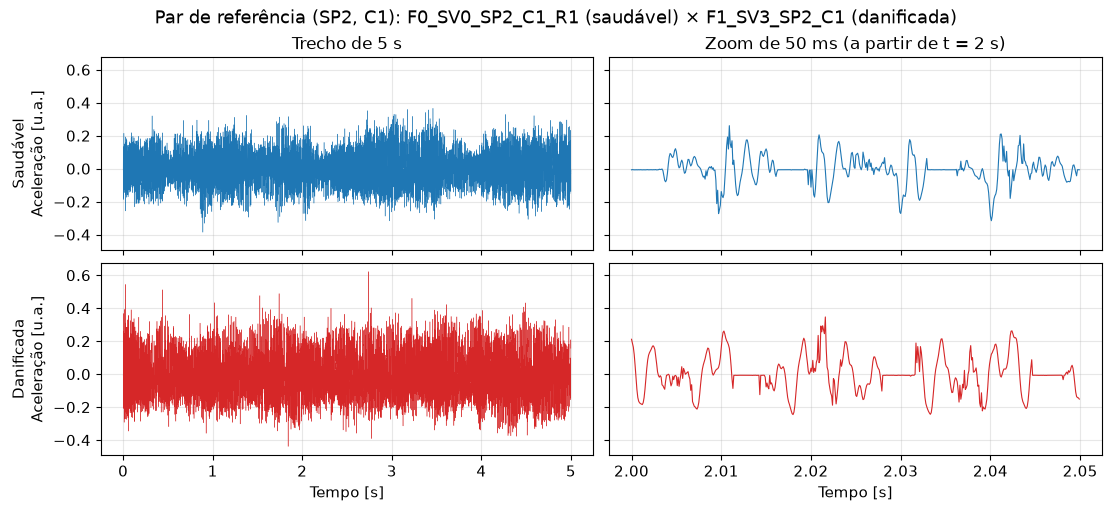

In [8]:
reg_s = carregar_registro(PASTA_DATASET / f'{PAR_REF[0]}.mat')
reg_d = carregar_registro(PASTA_DATASET / f'{PAR_REF[1]}.mat')

fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex='col', sharey=True)
for lin, (reg, cond) in enumerate([(reg_s, 'saudavel'), (reg_d, 'danificada')]):
    x = reg['piezo']['x']
    t = np.arange(len(x)) / FS
    axes[lin, 0].plot(t[:5 * FS], x[:5 * FS], color=CORES[cond], lw=0.3)
    axes[lin, 0].set_ylabel(f'{ROTULOS[cond]}\nAceleração [u.a.]')
    z0, z1 = int(2.0 * FS), int(2.05 * FS)
    axes[lin, 1].plot(t[z0:z1], x[z0:z1], color=CORES[cond], lw=0.8)
axes[0, 0].set_title('Trecho de 5 s')
axes[0, 1].set_title('Zoom de 50 ms (a partir de t = 2 s)')
for col in (0, 1):
    axes[1, col].set_xlabel('Tempo [s]')
fig.suptitle(f'Par de referência (SP2, C1): {PAR_REF[0]} (saudável) × {PAR_REF[1]} (danificada)')
salvar_figura(fig, 'tempo_par_referencia')
plt.show()

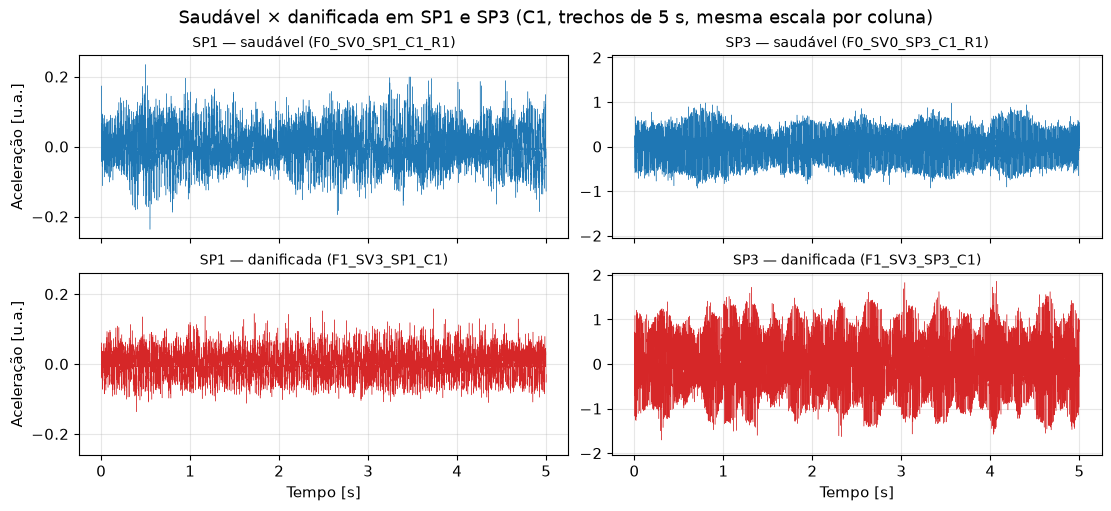

In [9]:
# Painel compacto: saudável × danificada em SP1 e SP3 (mesma C1)
pares = [('F0_SV0_SP1_C1_R1', 'F1_SV3_SP1_C1', 'SP1'),
         ('F0_SV0_SP3_C1_R1', 'F1_SV3_SP3_C1', 'SP3')]
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex=True)
for col, (rs, rd, sp) in enumerate(pares):
    xs = carregar_registro(PASTA_DATASET / f'{rs}.mat')['piezo']['x']
    xd = carregar_registro(PASTA_DATASET / f'{rd}.mat')['piezo']['x']
    t = np.arange(5 * FS) / FS
    ylim = 1.1 * max(np.abs(xs[:5 * FS]).max(), np.abs(xd[:5 * FS]).max())
    axes[0, col].plot(t, xs[:5 * FS], color=CORES['saudavel'], lw=0.3)
    axes[1, col].plot(t, xd[:5 * FS], color=CORES['danificada'], lw=0.3)
    axes[0, col].set_title(f'{sp} — saudável ({rs})', fontsize=10)
    axes[1, col].set_title(f'{sp} — danificada ({rd})', fontsize=10)
    for lin in (0, 1):
        axes[lin, col].set_ylim(-ylim, ylim)
    axes[1, col].set_xlabel('Tempo [s]')
for lin in (0, 1):
    axes[lin, 0].set_ylabel('Aceleração [u.a.]')
fig.suptitle('Saudável × danificada em SP1 e SP3 (C1, trechos de 5 s, mesma escala por coluna)')
salvar_figura(fig, 'tempo_sp1_sp3')
plt.show()

**Leitura das figuras.** Os sinais são oscilações rápidas de média zero, moduladas em amplitude, sem estrutura periódica visível a olho nu no trecho longo — o zoom de 50 ms revela a oscilação dominante (período da ordem de 10 ms em SP2, coerente com a componente de ~100 Hz identificada na Seção 3). No par de referência (SP2), a danificada aparenta amplitude um pouco maior que a saudável; em SP3 isso se repete, mas **em SP1 a saudável vibra mais que a danificada** — quantificado em 2.3. A diferença entre as condições é sutil no domínio do tempo: as formas de onda são qualitativamente parecidas, o que motiva a análise espectral.

### 2.2 Definições das características temporais (req. 3.2.2)

Para cada janela $x[n]$, $n = 0, \dots, N-1$ ($N = 10\,000$), calculamos **sobre o sinal bruto** (sem remover a média — a média é uma das características):

| Característica | Definição | Unidade | Significado |
|---|---|---|---|
| Média | $\mu = \frac{1}{N}\sum_{n} x[n]$ | u.a. | componente constante (DC) |
| RMS | $\sqrt{\frac{1}{N}\sum_{n} x[n]^2}$ | u.a. | intensidade efetiva da vibração |
| Potência média | $P = \frac{1}{N}\sum_{n} x[n]^2$ | u.a.² | energia por amostra; $P = \mathrm{RMS}^2$ |
| Desvio padrão | $\sigma = \sqrt{\frac{1}{N}\sum_{n}(x[n]-\mu)^2}$ (populacional, ddof = 0) | u.a. | dispersão em torno da média |
| Pico absoluto | $\max_n \lvert x[n] \rvert$ | u.a. | maior excursão instantânea |
| Pico a pico | $\max_n x[n] - \min_n x[n]$ | u.a. | faixa dinâmica total |
| Fator de crista | $\dfrac{\max_n \lvert x[n]\rvert}{\mathrm{RMS}}$ | adim. | quão "impulsivo" é o sinal |
| Curtose (extra) | de **Pearson** (não excedente): vale **3** para um sinal gaussiano | adim. | peso das caudas / impulsividade |
| Assimetria (extra) | momento central de 3ª ordem normalizado | adim. | assimetria da distribuição de amplitudes |

Curtose e assimetria são as características extras adotadas: falhas mecânicas costumam gerar impulsos repetitivos que engordam as caudas da distribuição de amplitudes, e a curtose é um indicador clássico disso em monitoramento de vibração.

### 2.3 Tabelas e gráficos comparativos (req. 3.2.3)

In [10]:
feats_tempo = ['media', 'rms', 'potencia_media', 'desvio_padrao', 'pico_absoluto',
               'pico_a_pico', 'fator_crista', 'curtose', 'assimetria']
resumo_t = (df_dedup.groupby(['condicao', 'velocidade'])[feats_tempo]
            .agg(['median', lambda s: s.quantile(0.75) - s.quantile(0.25)]))
resumo_t.columns = [f"{a}_{'mediana' if b == 'median' else 'iqr'}" for a, b in resumo_t.columns]
resumo_t.to_csv('results/resumo_tempo.csv')
print('Medianas por condição × velocidade (deduplicado); tabela completa com IQR em results/resumo_tempo.csv')
display(resumo_t[[c for c in resumo_t.columns if c.endswith('mediana')]].round(4))

Medianas por condição × velocidade (deduplicado); tabela completa com IQR em results/resumo_tempo.csv


media_mediana  rms_mediana  potencia_media_mediana  desvio_padrao_mediana  pico_absoluto_mediana  pico_a_pico_mediana  fator_crista_mediana  curtose_mediana  \
condicao   velocidade                                                                                                                                                                 
danificada 1                 -0.0011       0.0245                  0.0006                 0.0244                 0.1338               0.2335                5.4449           4.2538   
           2                 -0.0011       0.0924                  0.0085                 0.0924                 0.4100               0.7673                4.3839           3.8795   
           3                 -0.0015       0.2374                  0.0563                 0.2374                 0.8943               1.6950                3.7116           3.3947   
saudavel   1                 -0.0008       0.0393                  0.0015                 0.0393                 0.1862               0.3284                5.0999           4.1984   
           2                 -0.0008       0.0862                  0.0074                 0.0862                 0.3666               0.6958                4.3272           3.7746   
           3                 -0.0010       0.2071                  0.0429                 0.2071                 0.7551               1.3987                3.5626           3.2281   

                       assimetria_mediana  
condicao   velocidade                      
danificada 1                       0.3674  
           2                       0.0618  
           3                       0.0438  
saudavel   1                       0.2746  
           2                       0.1685  
           3                       0.0511

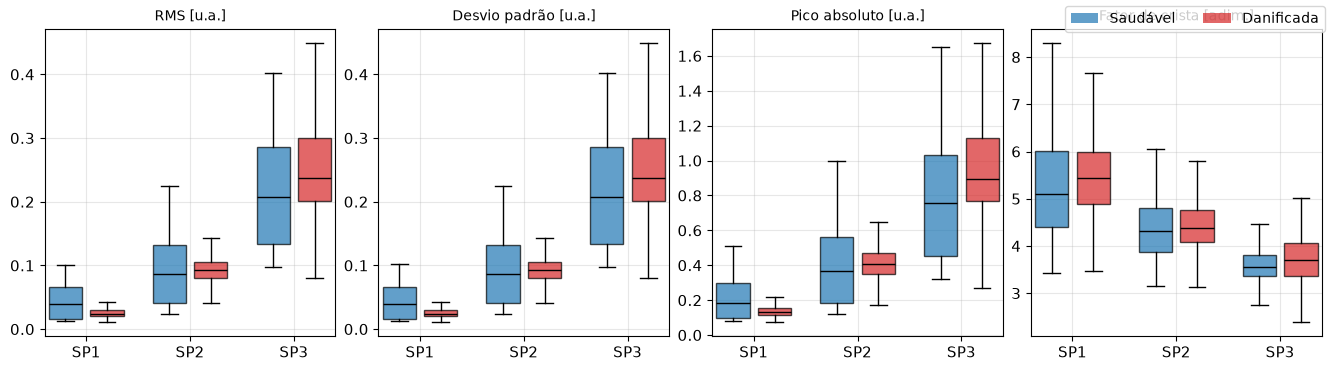

In [11]:
def boxplots_por_sp(dados, colunas, titulos, nome_figura, ylabel_unidade=None):
    '''Boxplots saudável × danificada lado a lado, agrupados por SP (dados deduplicados).'''
    fig, axes = plt.subplots(1, len(colunas), figsize=(3.3 * len(colunas), 3.6))
    for ax, feat, titulo in zip(np.atleast_1d(axes), colunas, titulos):
        vals, pos, cores = [], [], []
        for i, sp in enumerate([1, 2, 3]):
            for j, cond in enumerate(['saudavel', 'danificada']):
                vals.append(dados[(dados.velocidade == sp) & (dados.condicao == cond)][feat].dropna().values)
                pos.append(i * 2.5 + j)
                cores.append(CORES[cond])
        bp = ax.boxplot(vals, positions=pos, widths=0.8, patch_artist=True,
                        showfliers=False, medianprops={'color': 'black'})
        for patch, c in zip(bp['boxes'], cores):
            patch.set_facecolor(c); patch.set_alpha(0.7)
        ax.set_xticks([0.5, 3.0, 5.5]); ax.set_xticklabels(['SP1', 'SP2', 'SP3'])
        ax.set_title(titulo, fontsize=10)
    from matplotlib.patches import Patch
    fig.legend(handles=[Patch(facecolor=CORES[c], alpha=0.7, label=ROTULOS[c]) for c in CORES],
               loc='upper right', ncol=2)
    salvar_figura(fig, nome_figura)
    plt.show()

boxplots_por_sp(df_dedup, ['rms', 'desvio_padrao', 'pico_absoluto', 'fator_crista'],
                ['RMS [u.a.]', 'Desvio padrão [u.a.]', 'Pico absoluto [u.a.]', 'Fator de crista [adim.]'],
                'tempo_boxplots')

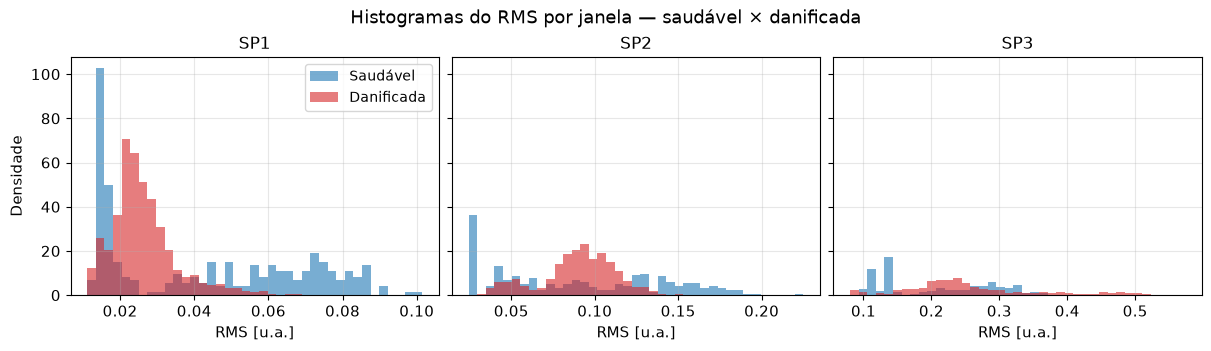

In [12]:
# Histogramas do RMS por janela, por velocidade
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, sp in zip(axes, [1, 2, 3]):
    sub = df_dedup[df_dedup.velocidade == sp]
    bins = np.linspace(sub.rms.min(), sub.rms.max(), 40)
    for cond in ['saudavel', 'danificada']:
        ax.hist(sub[sub.condicao == cond].rms, bins=bins, alpha=0.6,
                color=CORES[cond], label=ROTULOS[cond], density=True)
    ax.set_title(f'SP{sp}'); ax.set_xlabel('RMS [u.a.]')
axes[0].set_ylabel('Densidade')
axes[0].legend()
fig.suptitle('Histogramas do RMS por janela — saudável × danificada')
salvar_figura(fig, 'tempo_histogramas_rms')
plt.show()

### 2.4 Interpretação das características temporais (req. 3.2.4)

**O que diferencia as condições?** A **velocidade domina a intensidade**: o RMS mediano cresce quase 10× de SP1 para SP3 (saudável: 0,039 → 0,086 → 0,207 u.a.; danificada: 0,025 → 0,092 → 0,237 u.a.). Dentro de cada velocidade, a diferença entre condições é bem menor e **não tem sentido único**: a danificada vibra mais que a saudável em SP2 (+7 % no RMS mediano) e SP3 (+15 %), mas **menos** em SP1 (−38 %). Ou seja, **a hipótese "defeito ⇒ vibração mais intensa" não se sustenta em geral** neste dataset: vale para as velocidades média e alta, e se inverte na baixa. Os histogramas mostram ainda que as distribuições se sobrepõem bastante em SP2/SP3 — intensidade sozinha não separa as condições de forma confiável.

Curtose (3,2–4,3) e assimetria dão sinais fracos: a curtose mediana fica pouco acima de 3 (caudas levemente mais pesadas que uma gaussiana) e cai com a velocidade nas duas condições; o fator de crista se comporta de forma parecida (5,4 → 3,7 na danificada), refletindo mais a velocidade que a condição.

**Quais medidas são redundantes?** Por construção, RMS² = potência média, e como a média ≈ 0 no piezo, RMS ≈ desvio padrão — as três carregam a mesma informação (correlação de Spearman = 1,000 entre elas, ver Seção 4). Pico absoluto e pico a pico também são quase intercambiáveis (ρ = 0,996): em sinais de média zero e razoavelmente simétricos, o pico a pico ≈ 2 × pico absoluto. O conjunto temporal efetivamente independente é: {RMS, pico absoluto, fator de crista, curtose, assimetria, média}.

**Relação RMS × potência e efeito da componente média.** Vale a identidade $\mathrm{RMS}^2 = P = \sigma^2 + \mu^2$: a potência média soma a potência da componente DC ($\mu^2$) e a das flutuações ($\sigma^2$). A célula abaixo verifica isso numericamente e contrasta o piezo (que não mede DC) com o eixo Z da IMU (que mede a gravidade).

In [13]:
# RMS² = P = σ² + μ²: verificação numérica no par de referência
for reg, nome in [(reg_s, PAR_REF[0] + ' (saudável)'), (reg_d, PAR_REF[1] + ' (danificada)')]:
    x = reg['piezo']['x']
    mu, sig = x.mean(), x.std(ddof=0)
    P = np.mean(x**2)
    print(f'{nome} — piezo:')
    print(f'  μ = {mu:+.5f} u.a. | σ = {sig:.5f} | RMS = {np.sqrt(P):.5f} | '
          f'P = {P:.6f} | σ² + μ² = {sig**2 + mu**2:.6f}  (RMS ≈ σ, pois μ ≈ 0)')
    z = reg['imu']['xyz'][2]   # eixo Z da IMU, em m/s²
    muz, sigz = z.mean(), z.std(ddof=0)
    print(f'  IMU eixo Z: μ = {muz:.3f} m/s² | σ = {sigz:.3f} | RMS = {np.sqrt(np.mean(z**2)):.3f}'
          f'  (RMS >> σ: a gravidade domina a potência)')

F0_SV0_SP2_C1_R1 (saudável) — piezo:
  μ = -0.00120 u.a. | σ = 0.09375 | RMS = 0.09376 | P = 0.008791 | σ² + μ² = 0.008791  (RMS ≈ σ, pois μ ≈ 0)
  IMU eixo Z: μ = 9.719 m/s² | σ = 3.675 | RMS = 10.391  (RMS >> σ: a gravidade domina a potência)
F1_SV3_SP2_C1 (danificada) — piezo:
  μ = -0.00125 u.a. | σ = 0.11598 | RMS = 0.11599 | P = 0.013454 | σ² + μ² = 0.013454  (RMS ≈ σ, pois μ ≈ 0)
  IMU eixo Z: μ = 9.720 m/s² | σ = 3.989 | RMS = 10.507  (RMS >> σ: a gravidade domina a potência)


**Interpretação (componente média).** No piezo, μ ≈ −0,001 u.a. e RMS = σ até a 4ª casa decimal (ex.: saudável de referência: RMS = 0,09376, σ = 0,09375): toda a potência está nas flutuações. No eixo Z da IMU, μ ≈ 9,72 m/s² (gravidade) e o RMS (≈ 10,4 m/s²) é quase o triplo do σ (≈ 3,7 m/s²): a componente DC responde por (9,72/10,39)² ≈ 87 % da potência total, sem relação com a vibração. A lição prática: **RMS e potência média só medem "intensidade de vibração" se a componente média for nula ou removida** — caso contrário, convém usar o desvio padrão (ou subtrair μ antes).

## Seção 3 — Análise no domínio da frequência (req. 3.3) — seção central

### 3.1 FFT, eixo de frequências e normalização (req. 3.3.1)

Cada janela tem $N = 10\,000$ amostras a $f_s = 10\,000$ Hz. A DFT (calculada por FFT real, `np.fft.rfft`) produz $K = N/2 + 1 = 5\,001$ raias nas frequências $f_k = k \cdot f_s / N$ (`np.fft.rfftfreq`), de 0 Hz a Nyquist ($f_s/2 = 5\,000$ Hz), com espaçamento $\Delta f = f_s/N = 1$ Hz.

**Procedimento por janela:** (i) remoção da média (evita que a raia DC domine o espectro); (ii) multiplicação pela **janela de Hann** $w[n]$ (reduz o vazamento espectral causado pelo truncamento em 1 s); (iii) FFT e **normalização de amplitude**
$$A(f_k) = \frac{2\,\lvert X(f_k)\rvert}{\sum_n w[n]}, \qquad \text{(sem o fator 2 em } f_0 = 0 \text{ e em } f_{N/2} = f_s/2\text{)}$$
que compensa o ganho da janela de Hann e torna o espectro **unilateral**: uma senoide de amplitude $A$ aparece como um pico de altura ≈ $A$ (em u.a.). O fator 2 rebate a energia das frequências negativas sobre as positivas, exceto em DC e Nyquist, que não têm espelho.

Para as **potências** (por banda e total) usamos a **PSD unilateral** via `scipy.signal.periodogram(window='hann', detrend='constant', scaling='density')`, em u.a.²/Hz, integrada na banda — normalização adequada quando o interesse é energia, e consistente com o teorema de Parseval, verificado numericamente abaixo.

In [14]:
# Verificação numérica de Parseval numa janela do registro saudável de referência
x = janelar(reg_s['piezo']['x'])[0]
n = x.size
w = signal.windows.hann(n)
xw = (x - x.mean()) * w
X = np.fft.rfft(xw)
energia_tempo = np.sum(xw**2)
mod2 = np.abs(X)**2
energia_freq = (mod2[0] + 2 * mod2[1:-1].sum() + mod2[-1]) / n   # DFT unilateral
print(f'Σ x_w[n]²            = {energia_tempo:.6f} u.a.²')
print(f'(1/N)·Σ |X(f_k)|²     = {energia_freq:.6f} u.a.²   (unilateral, DC e Nyquist sem dobro)')
print(f'diferença relativa    = {abs(energia_tempo - energia_freq) / energia_tempo:.2e}')
# e a potência total da PSD deve bater com a potência do sinal janelado (a menos da normalização da janela)
f_p, P = psd(x)
print(f'∫PSD df = {np.trapezoid(P, f_p):.6f} u.a.²  ×  potência do sinal sem média = {np.mean((x - x.mean())**2):.6f} u.a.²')

Σ x_w[n]²            = 17.429605 u.a.²
(1/N)·Σ |X(f_k)|²     = 17.429605 u.a.²   (unilateral, DC e Nyquist sem dobro)
diferença relativa    = 2.04e-16
∫PSD df = 0.004648 u.a.²  ×  potência do sinal sem média = 0.005955 u.a.²


**Leitura.** A igualdade de Parseval vale com erro relativo da ordem de 10⁻¹⁶ (precisão de máquina): a energia calculada no tempo e na frequência é a mesma, confirmando a construção do eixo e da normalização. A integral da PSD também coincide com a potência do sinal (sem média) — o `periodogram` do SciPy já compensa internamente o ganho da janela de Hann.

### 3.2 Espectros de magnitude comparativos (req. 3.3.2)

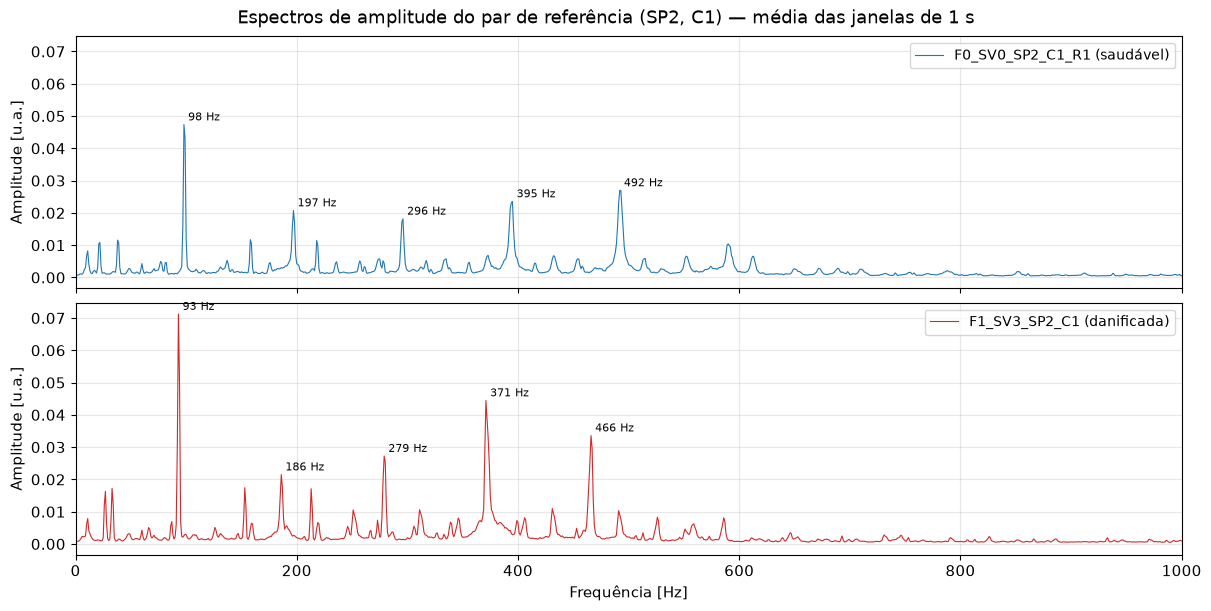

In [15]:
# (a) Par de referência: espectro médio de amplitude sobre as janelas de cada registro
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, reg, cond in [(axes[0], reg_s, 'saudavel'), (axes[1], reg_d, 'danificada')]:
    jan = janelar(reg['piezo']['x'])
    A_med = np.mean([espectro_amplitude(jan[i])[1] for i in range(jan.shape[0])], axis=0)
    ax.plot(f_esp, A_med, color=CORES[cond], lw=0.8,
            label=f"{reg['meta']['registro_id']} ({ROTULOS[cond].lower()})")
    # anota os 5 maiores picos até 1000 Hz
    sel = f_esp <= 1000
    idx, props = signal.find_peaks(A_med[sel], height=0.1 * A_med[sel].max(), distance=5)
    for i in np.argsort(props['peak_heights'])[::-1][:5]:
        ax.annotate(f'{f_esp[sel][idx[i]]:.0f} Hz', (f_esp[sel][idx[i]], props['peak_heights'][i]),
                    textcoords='offset points', xytext=(3, 3), fontsize=8)
    ax.set_xlim(0, 1000); ax.legend(loc='upper right')
    ax.set_ylabel('Amplitude [u.a.]')
axes[1].set_xlabel('Frequência [Hz]')
fig.suptitle('Espectros de amplitude do par de referência (SP2, C1) — média das janelas de 1 s')
salvar_figura(fig, 'freq_par_referencia')
plt.show()

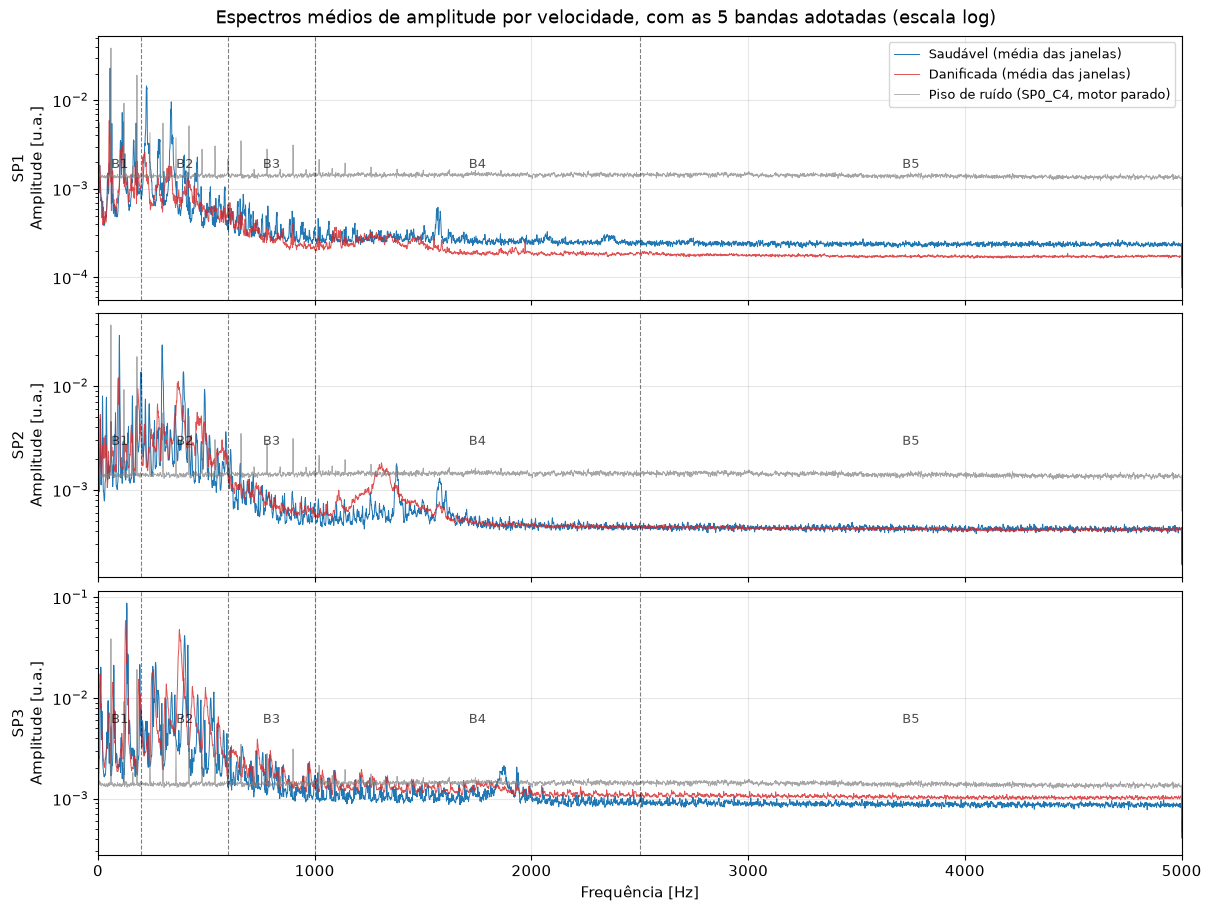

In [16]:
# (b) Espectros médios por condição × velocidade (0–5 kHz, escala log) com as bandas e o piso de ruído
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, sp in zip(axes, [1, 2, 3]):
    ax.semilogy(f_esp, espectros[f'saudavel_SP{sp}'], color=CORES['saudavel'], lw=0.7,
                label='Saudável (média das janelas)')
    ax.semilogy(f_esp, espectros[f'danificada_SP{sp}'], color=CORES['danificada'], lw=0.7,
                alpha=0.8, label='Danificada (média das janelas)')
    ax.semilogy(f_esp, espectros['ruido_SP0_C4'], color='gray', lw=0.6, alpha=0.7,
                label='Piso de ruído (SP0_C4, motor parado)')
    for nome, (f1, f2) in BANDAS.items():
        ax.axvline(f2, color='k', ls='--', lw=0.8, alpha=0.5)
        ax.text((f1 + f2) / 2, 0.5, nome.split('_')[0], transform=ax.get_xaxis_transform(),
                ha='center', fontsize=9, alpha=0.7)
    ax.set_ylabel(f'SP{sp}\nAmplitude [u.a.]')
    ax.set_xlim(0, 5000)
axes[0].legend(loc='upper right', fontsize=9)
axes[2].set_xlabel('Frequência [Hz]')
fig.suptitle('Espectros médios de amplitude por velocidade, com as 5 bandas adotadas (escala log)')
salvar_figura(fig, 'freq_espectros_medios_bandas')
plt.show()

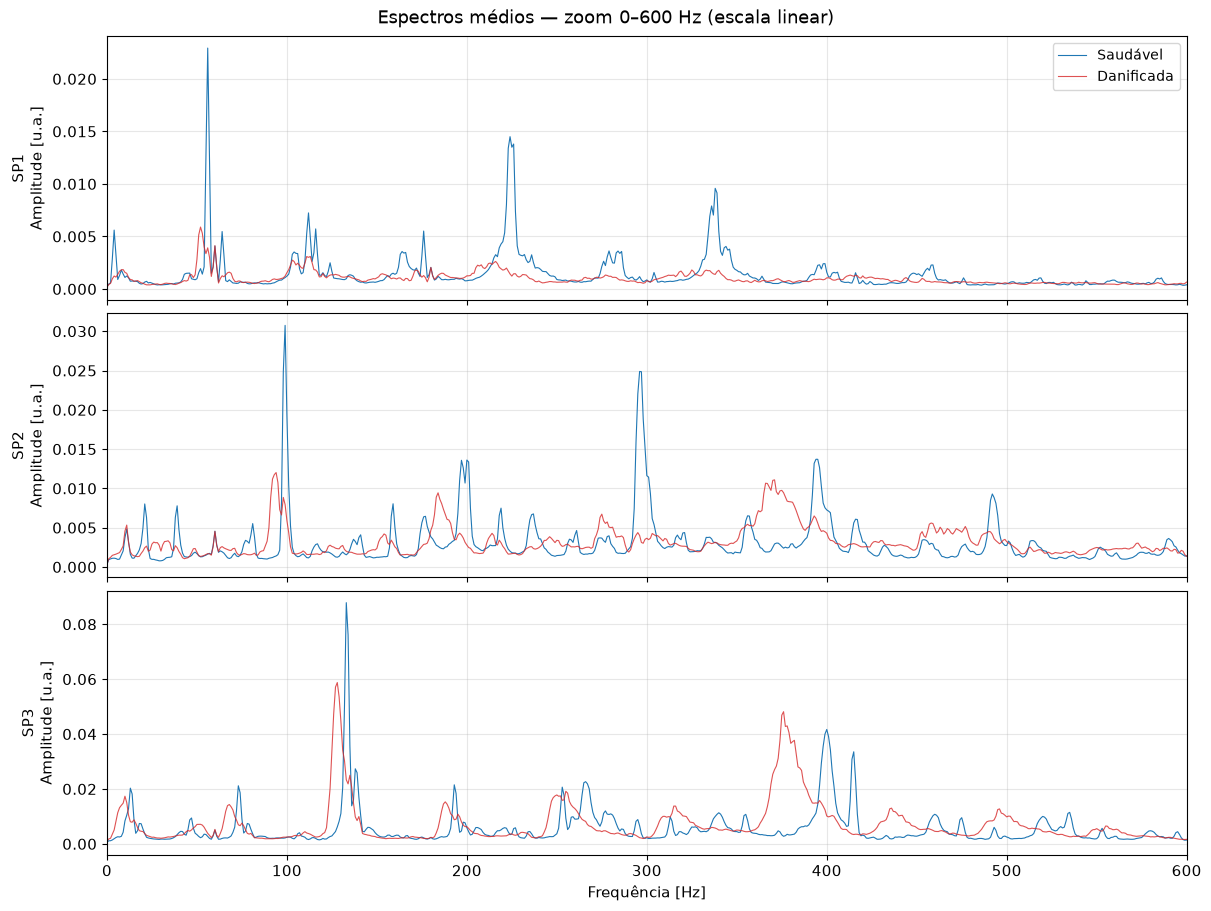

In [17]:
# (c) Zoom 0–600 Hz em escala linear: região dos picos principais
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, sp in zip(axes, [1, 2, 3]):
    ax.plot(f_esp, espectros[f'saudavel_SP{sp}'], color=CORES['saudavel'], lw=0.8, label='Saudável')
    ax.plot(f_esp, espectros[f'danificada_SP{sp}'], color=CORES['danificada'], lw=0.8,
            alpha=0.8, label='Danificada')
    ax.set_xlim(0, 600)
    ax.set_ylabel(f'SP{sp}\nAmplitude [u.a.]')
axes[0].legend(loc='upper right')
axes[2].set_xlabel('Frequência [Hz]')
fig.suptitle('Espectros médios — zoom 0–600 Hz (escala linear)')
salvar_figura(fig, 'freq_espectros_zoom600')
plt.show()

In [18]:
# Principais picos (até 1000 Hz) dos espectros médios, por condição × velocidade
def maiores_picos(A, f, fmax=1000, n_picos=5):
    sel = f <= fmax
    idx, props = signal.find_peaks(A[sel], height=0.1 * A[sel][1:].max(), distance=5)
    ordem = np.argsort(props['peak_heights'])[::-1][:n_picos]
    return sorted(zip(f[sel][idx[ordem]], props['peak_heights'][ordem]), key=lambda p: -p[1])

tab_picos = []
for sp in [1, 2, 3]:
    for cond in ['saudavel', 'danificada']:
        for rank, (ff, aa) in enumerate(maiores_picos(espectros[f'{cond}_SP{sp}'], f_esp), 1):
            tab_picos.append({'velocidade': sp, 'condicao': cond, 'rank': rank,
                              'freq_hz': round(ff, 1), 'amplitude_ua': round(aa, 4)})
tab_picos = pd.DataFrame(tab_picos)
display(tab_picos.pivot_table(index=['velocidade', 'rank'], columns='condicao',
                              values=['freq_hz', 'amplitude_ua']).round(4))

amplitude_ua             freq_hz         
condicao          danificada saudavel danificada saudavel
velocidade rank                                          
1          1          0.0059   0.0229       52.0     56.0
           2          0.0041   0.0145       60.0    224.0
           3          0.0031   0.0096      113.0    338.0
           4          0.0027   0.0072      103.0    112.0
           5          0.0026   0.0056      216.0      4.0
2          1          0.0120   0.0307       94.0     99.0
           2          0.0111   0.0249      371.0    296.0
           3          0.0107   0.0137      366.0    394.0
           4          0.0094   0.0136      184.0    200.0
           5          0.0067   0.0093      275.0    492.0
3          1          0.0588   0.0879      128.0    133.0
           2          0.0481   0.0417      376.0    400.0
           3          0.0377   0.0335      382.0    415.0
           4          0.0250   0.0273      135.0    138.0
           5          0.0192   0.0227      255.0    266.0

**Leitura dos espectros.** Três observações estruturais:
1. **Quase todo o conteúdo está abaixo de ~2 000 Hz**; acima disso os espectros são planos e próximos do piso de ruído (`SP0_C4`). O piso, por sua vez, exibe picos estreitos em 60, 120, 180 Hz etc. — múltiplos de 60 Hz com os motores parados, cuja hipótese mais plausível é interferência da rede elétrica, não vibração mecânica.
2. Os espectros com motor são **harmônicos**: uma componente fundamental dependente da velocidade (saudável: ≈ 56 Hz em SP1, ≈ 99 Hz em SP2, ≈ 133 Hz em SP3) e múltiplos inteiros dela (SP2 saudável: 99, 198(=2×), 296(=3×), 394(=4×), 492(=5×) Hz). Como o RPM não é documentado, tratamos como hipótese que a fundamental acompanha a rotação (e seus harmônicos, a passagem das pás) — as razões inteiras entre os picos sustentam essa estrutura, sem afirmarmos a causa física de cada pico.
3. **O dano desloca e redistribui os picos**: a fundamental da danificada fica sistematicamente ~4–5 % **abaixo** da saudável na mesma SP (SP2: 94 × 99 Hz; SP3: 128 × 133 Hz), e surgem "lombadas" largas típicas da condição danificada (ex.: ≈ 370 Hz em SP2/SP3) onde a saudável tem picos estreitos em outras posições. Em SP1, a danificada tem amplitude espectral geral menor (coerente com o RMS menor visto no tempo).

### 3.3 Definições das características espectrais (req. 3.3.3)

Para cada janela (mesma convenção em todas as condições):

| Característica | Definição | Unidade |
|---|---|---|
| Frequência dominante | $\arg\max_f A(f)$, excluindo a raia DC | Hz |
| Magnitude do pico dominante | $\max_f A(f)$ | u.a. |
| Potência na banda $B$ | $\int_B S(f)\,df$ (PSD unilateral $S$, regra do trapézio) + fração $/\!\!$ potência total | u.a.² |
| Centroide espectral | $\dfrac{\sum_k f_k\,S(f_k)}{\sum_k S(f_k)}$ — "centro de massa" do espectro | Hz |
| Entropia espectral | $-\dfrac{\sum_k p_k \log_2 p_k}{\log_2 K}$, com $p_k = S(f_k)/\sum_j S(f_j)$ — 0 = tom puro, 1 = ruído branco | adim. (0–1) |

**Bandas adotadas** (definidas após inspeção dos espectros médios): **B1 = 0–200 Hz** (fundamental e primeiros harmônicos), **B2 = 200–600 Hz** (harmônicos superiores — a região onde as condições mais diferem), **B3 = 600–1000 Hz** (cauda da região harmônica), **B4 = 1000–2500 Hz** e **B5 = 2500–5000 Hz** (alta frequência, próxima do piso — documentam que o dano quase não altera essa região). A divisão em 200–600 / 600–1000 Hz foi escolhida porque agrupar tudo em 200–1000 Hz diluía o contraste entre condições concentrado em 200–600 Hz.

### 3.4 Tabelas e gráficos das características espectrais (req. 3.3.4)

In [19]:
feats_freq = (['freq_dominante', 'mag_pico_dominante', 'potencia_total',
               'centroide_espectral', 'entropia_espectral']
              + [f'pot_{b}' for b in BANDAS] + [f'frac_{b}' for b in BANDAS])
resumo_f = (df_dedup.groupby(['condicao', 'velocidade'])[feats_freq]
            .agg(['median', lambda s: s.quantile(0.75) - s.quantile(0.25)]))
resumo_f.columns = [f"{a}_{'mediana' if b == 'median' else 'iqr'}" for a, b in resumo_f.columns]
resumo_f.to_csv('results/resumo_frequencia.csv')
print('Medianas (deduplicado); tabela completa com IQR em results/resumo_frequencia.csv')
display(resumo_f[[c for c in resumo_f.columns if c.endswith('mediana')]].round(4))

Medianas (deduplicado); tabela completa com IQR em results/resumo_frequencia.csv


freq_dominante_mediana  mag_pico_dominante_mediana  potencia_total_mediana  centroide_espectral_mediana  entropia_espectral_mediana  pot_B1_0_200_mediana  \
condicao   velocidade                                                                                                                                                              
danificada 1                             57.0                      0.0145                  0.0006                     469.6508                      0.6064                0.0003   
           2                            365.0                      0.0545                  0.0083                     457.3034                      0.5334                0.0018   
           3                            136.0                      0.1885                  0.0566                     364.6888                      0.4291                0.0196   
saudavel   1                             57.0                      0.0252                  0.0015                     393.6624                      0.5267                0.0006   
           2                            294.0                      0.0588                  0.0066                     405.5477                      0.5020                0.0020   
           3                            399.0                      0.1572                  0.0412                     396.1103                      0.3658                0.0138   

                       pot_B2_200_600_mediana  pot_B3_600_1000_mediana  pot_B4_1000_2500_mediana  pot_B5_2500_5000_mediana  frac_B1_0_200_mediana  frac_B2_200_600_mediana  frac_B3_600_1000_mediana  \
condicao   velocidade                                                                                                                                                                                  
danificada 1                           0.0002                   0.0000                    0.0000                    0.0000                 0.4455                   0.3693                    0.0302   
           2                           0.0053                   0.0001                    0.0005                    0.0002                 0.2554                   0.6388                    0.0169   
           3                           0.0302                   0.0007                    0.0009                    0.0011                 0.3942                   0.5552                    0.0124   
saudavel   1                           0.0004                   0.0000                    0.0001                    0.0001                 0.3615                   0.4922                    0.0181   
           2                           0.0038                   0.0002                    0.0003                    0.0002                 0.2715                   0.6035                    0.0154   
           3                           0.0199                   0.0005                    0.0008                    0.0008                 0.3824                   0.5653                    0.0118   

                       frac_B4_1000_2500_mediana  frac_B5_2500_5000_mediana  
condicao   velocidade                                                        
danificada 1                              0.0543                     0.0497  
           2                              0.0504                     0.0235  
           3                              0.0163                     0.0183  
saudavel   1                              0.0330                     0.0343  
           2                              0.0273                     0.0248  
           3                              0.0192                     0.0204

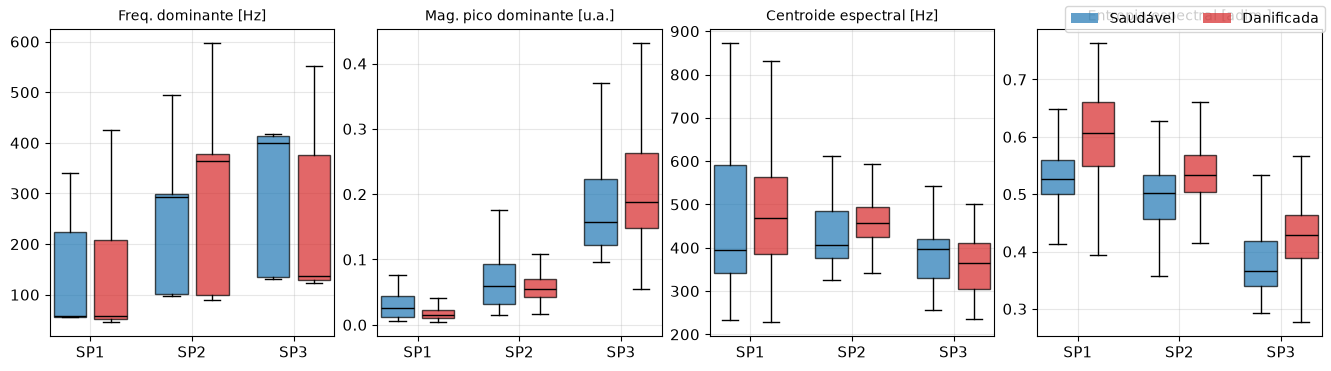

In [20]:
boxplots_por_sp(df_dedup, ['freq_dominante', 'mag_pico_dominante', 'centroide_espectral', 'entropia_espectral'],
                ['Freq. dominante [Hz]', 'Mag. pico dominante [u.a.]',
                 'Centroide espectral [Hz]', 'Entropia espectral [adim.]'],
                'freq_boxplots')

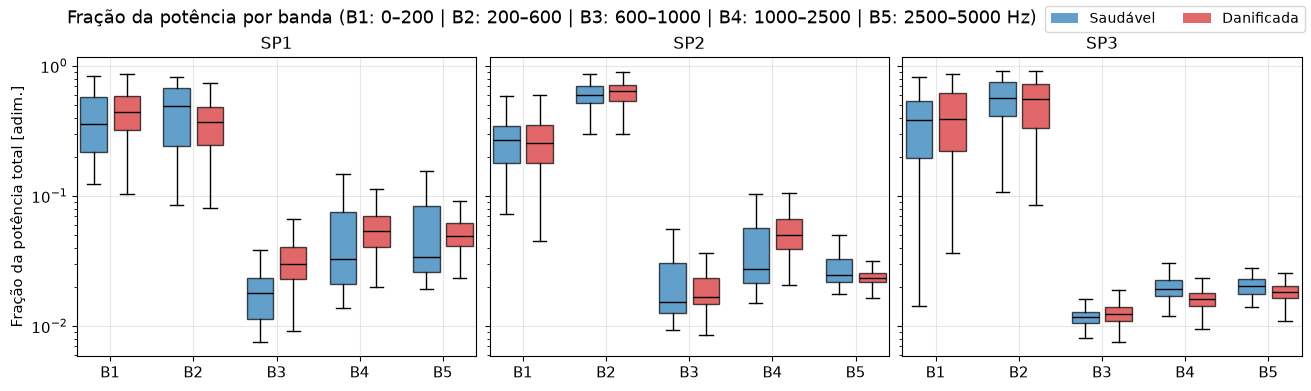

In [21]:
# Fração da potência por banda: boxplots agrupados, um painel por velocidade
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
nomes_b = list(BANDAS.keys())
for ax, sp in zip(axes, [1, 2, 3]):
    sub = df_dedup[df_dedup.velocidade == sp]
    vals, pos, cores = [], [], []
    for i, b in enumerate(nomes_b):
        for j, cond in enumerate(['saudavel', 'danificada']):
            vals.append(sub[sub.condicao == cond][f'frac_{b}'].values)
            pos.append(i * 2.5 + j)
            cores.append(CORES[cond])
    bp = ax.boxplot(vals, positions=pos, widths=0.8, patch_artist=True,
                    showfliers=False, medianprops={'color': 'black'})
    for patch, c in zip(bp['boxes'], cores):
        patch.set_facecolor(c); patch.set_alpha(0.7)
    ax.set_xticks([0.5 + 2.5 * i for i in range(len(nomes_b))])
    ax.set_xticklabels([b.split('_')[0] for b in nomes_b])
    ax.set_yscale('log')
    ax.set_title(f'SP{sp}')
axes[0].set_ylabel('Fração da potência total [adim.]')
from matplotlib.patches import Patch
fig.legend(handles=[Patch(facecolor=CORES[c], alpha=0.7, label=ROTULOS[c]) for c in CORES],
           loc='upper right', ncol=2)
fig.suptitle('Fração da potência por banda (B1: 0–200 | B2: 200–600 | B3: 600–1000 | B4: 1000–2500 | B5: 2500–5000 Hz)', x=0.42)
salvar_figura(fig, 'freq_potencia_bandas')
plt.show()

### 3.5 Interpretação dos espectros (req. 3.3.5)

**Picos relevantes.** Ver tabela de picos em 3.2 e a leitura dos espectros: estrutura harmônica com fundamental de ≈ 56/99/133 Hz (saudável, SP1/SP2/SP3) e ≈ 52/94/128 Hz (danificada) — o dano desloca a fundamental ~4–5 % para baixo, consistente em SP2 e SP3.

**Diferenças entre condições, por característica:**
- **Entropia espectral** é a diferença mais consistente: a danificada tem entropia mediana **maior** em todas as velocidades (SP1: 0,61 × 0,53; SP2: 0,53 × 0,50; SP3: 0,43 × 0,37) — o dano **espalha** a energia do espectro, reduzindo a concentração nos picos harmônicos.
- **Frações de potência por banda**: o contraste mais forte está em B4 (1000–2500 Hz): mediana 0,050 (danificada) × 0,027 (saudável) em SP2, invertendo em SP3 (0,016 × 0,019). Em B2 (200–600 Hz) a danificada concentra mais potência em SP2/SP3.
- **Frequência dominante por janela** é instável como característica: como vários harmônicos têm amplitudes próximas, a raia vencedora alterna entre eles de janela para janela (medianas: 294 Hz saudável × 365 Hz danificada em SP2; 399 × 136 Hz em SP3). Ela separa as condições, mas de forma "categórica" (qual harmônico vence), não como medida contínua.
- **Centroide espectral**: mais alto na danificada em SP1/SP2 (ex.: 457 × 406 Hz em SP2) e mais baixo em SP3 (365 × 396 Hz) — de novo, direção dependente da velocidade.

**O que o espectro revela que o tempo não mostra?** No tempo, as formas de onda das duas condições são qualitativamente parecidas e a diferença se resume à intensidade (com direção inconsistente entre SPs). No espectro aparecem assinaturas estruturais invisíveis no tempo: o deslocamento da fundamental, o surgimento de lombadas largas em posições próprias da condição danificada e o espalhamento de energia medido pela entropia — diferenças de **composição** da vibração, não de intensidade.

### 3.6 Resolução espectral: efeito da duração do trecho (req. 3.3.6)

A FFT de um trecho de duração $T$ tem espaçamento $\Delta f = f_s/N = 1/T$. Comparamos trechos de **0,1 s, 1 s e 10 s** do mesmo registro (o saudável de referência, `F0_SV0_SP2_C1_R1`).

 duração [s]      N  Δf = fs/N [Hz]
         0.1   1000            10.0
         1.0  10000             1.0
        10.0 100000             0.1


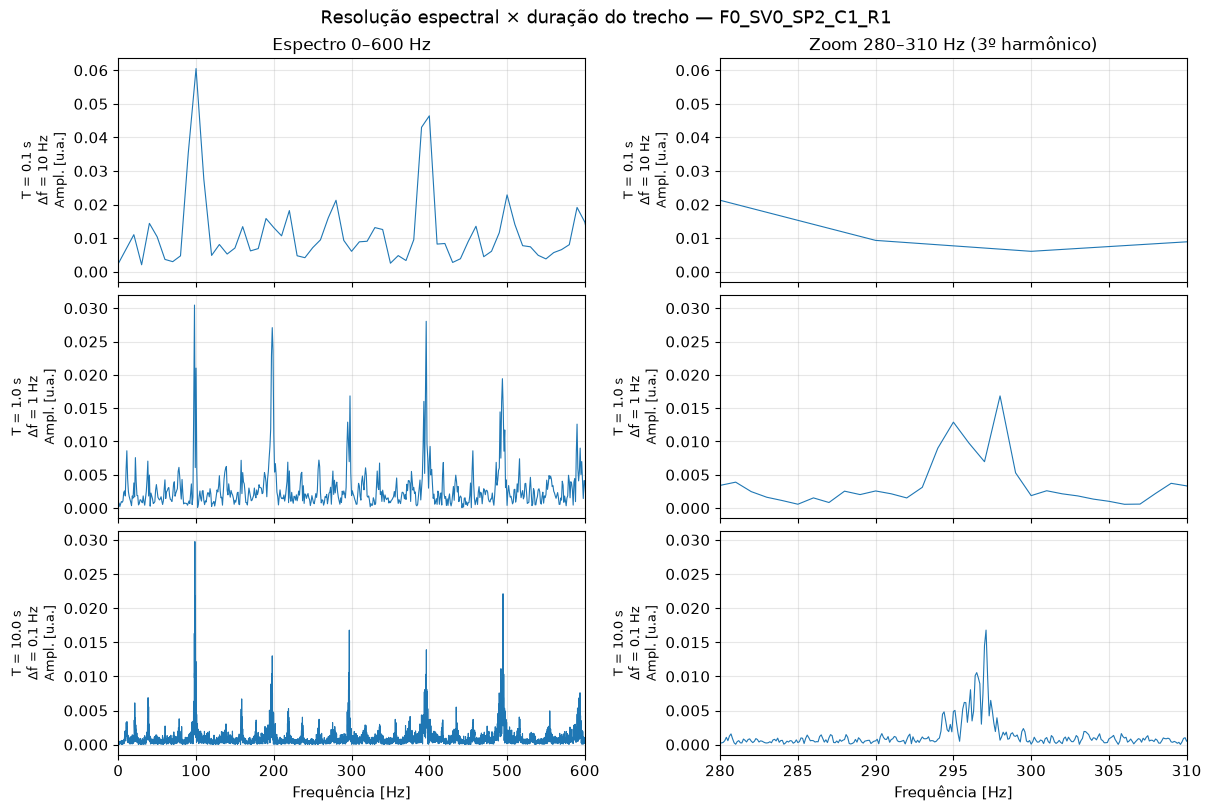

In [22]:
duracoes = [0.1, 1.0, 10.0]
x_full = reg_s['piezo']['x']
print(pd.DataFrame({'duração [s]': duracoes,
                    'N': [int(d * FS) for d in duracoes],
                    'Δf = fs/N [Hz]': [FS / int(d * FS) for d in duracoes]}).to_string(index=False))

fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex='col')
for lin, dur in enumerate(duracoes):
    n = int(dur * FS)
    f_r, A_r = espectro_amplitude(x_full[:n], fs=FS)
    for col, (fmin, fmax) in enumerate([(0, 600), (280, 310)]):
        axes[lin, col].plot(f_r, A_r, color=CORES['saudavel'], lw=0.8)
        axes[lin, col].set_xlim(fmin, fmax)
        axes[lin, col].set_ylabel(f'T = {dur} s\nΔf = {FS/n:g} Hz\nAmpl. [u.a.]', fontsize=9)
axes[0, 0].set_title('Espectro 0–600 Hz')
axes[0, 1].set_title('Zoom 280–310 Hz (3º harmônico)')
for col in (0, 1):
    axes[2, col].set_xlabel('Frequência [Hz]')
fig.suptitle(f'Resolução espectral × duração do trecho — {PAR_REF[0]}')
salvar_figura(fig, 'freq_resolucao')
plt.show()

**Interpretação (resolução).** Com T = 0,1 s (Δf = 10 Hz), o espectro é uma versão borrada: cada pico vira um lóbulo largo e componentes separadas por menos de ~10 Hz se fundem — no zoom de 280–310 Hz há um único lóbulo. Com T = 1 s (Δf = 1 Hz), os harmônicos aparecem como picos bem definidos — resolução suficiente para separar os picos deste sinal, que distam ≈ 99 Hz entre si. Com T = 10 s (Δf = 0,1 Hz) revela-se a estrutura fina: o "pico" de ≈ 296 Hz se decompõe em componentes próximas que o Δf = 1 Hz fundia, e nota-se que as raias têm largura própria (a rotação flutua ao longo de 10 s, alargando a linha). A escolha da duração é, portanto, um compromisso: janelas curtas dão muitas amostras estatísticas por registro, mas só distinguem picos afastados mais de 1/T Hz; a janela de 1 s adotada equilibra resolução (1 Hz) e quantidade de janelas (5 280).

### 3.7 Amostragem e aliasing (req. 3.3.7)

Reduzimos a taxa de um registro SP3 (`F0_SV0_SP3_C1_R1`) de 10 kHz para **fs' = 500 Hz** (fator 20; nova Nyquist = 250 Hz), de duas formas: (i) **subamostragem ingênua** `x[::20]`, sem filtro; (ii) **decimação com filtro anti-aliasing** (`scipy.signal.decimate`, FIR). Pelo critério de Nyquist, componentes acima de 250 Hz não podem ser representadas a 500 Hz: na subamostragem ingênua elas **rebatem** para a frequência aparente $f_{alias} = \lvert f - k\,f_s' \rvert$ (com $k$ inteiro que leve o resultado a $[0, f_s'/2]$). Antes de plotar, calculamos as frequências aparentes previstas dos picos acima de 250 Hz.

Previsão do rebatimento (fs' = 500 Hz, Nyquist = 250 Hz):


,f_original_hz,previsto
0,14.8,inalterada (abaixo de Nyquist)
1,74.5,inalterada (abaixo de Nyquist)
2,134.4,inalterada (abaixo de Nyquist)
3,194.0,inalterada (abaixo de Nyquist)
4,254.7,|254.7 − 1·500| = 245.3 Hz
5,403.6,|403.6 − 1·500| = 96.4 Hz


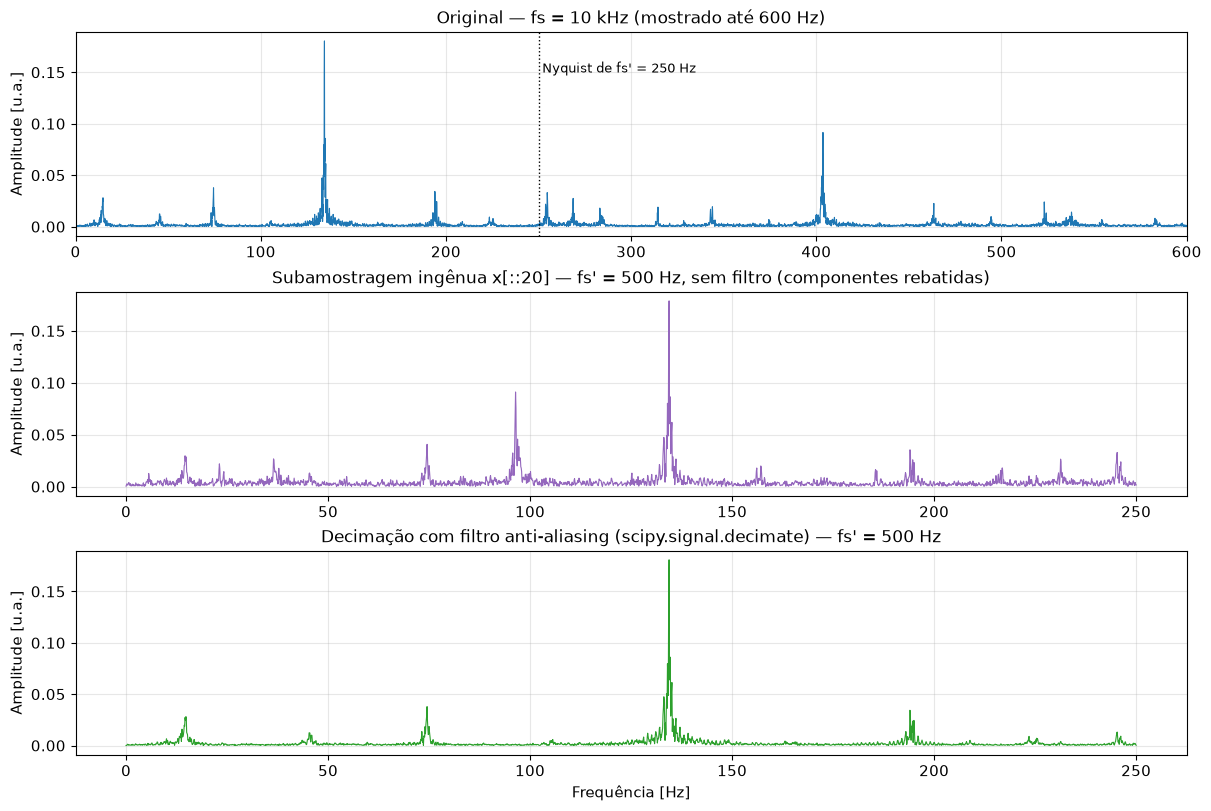

f =  254.7 Hz -> alias previsto  245.3 Hz | amplitude no espectro ingênuo perto de 245 Hz: 0.0328 u.a. | no decimado: 0.0131 u.a.
f =  403.6 Hz -> alias previsto   96.4 Hz | amplitude no espectro ingênuo perto de 96 Hz: 0.0911 u.a. | no decimado: 0.0013 u.a.


In [23]:
reg3 = carregar_registro(PASTA_DATASET / 'F0_SV0_SP3_C1_R1.mat')
x3 = reg3['piezo']['x']
FS_NOVO = 500.0

# picos do espectro original (trecho de 10 s para Δf = 0,1 Hz)
f_o, A_o = espectro_amplitude(x3[:int(10 * FS)], fs=FS)
sel = f_o <= 1000
idx, props = signal.find_peaks(A_o[sel], height=0.15 * A_o[sel].max(), distance=20)
picos_orig = sorted(f_o[sel][idx[np.argsort(props['peak_heights'])[::-1][:6]]])
print('Previsão do rebatimento (fs\' = 500 Hz, Nyquist = 250 Hz):')
tab_alias = []
for p in picos_orig:
    if p > FS_NOVO / 2:
        k = round(p / FS_NOVO)
        tab_alias.append({'f_original_hz': round(p, 1), 'previsto': f'|{p:.1f} − {k}·500| = {abs(p - k * FS_NOVO):.1f} Hz'})
    else:
        tab_alias.append({'f_original_hz': round(p, 1), 'previsto': 'inalterada (abaixo de Nyquist)'})
display(pd.DataFrame(tab_alias))

x_ingenuo = x3[::20]
x_decimado = signal.decimate(x3, 20, ftype='fir', zero_phase=True)
fig, axes = plt.subplots(3, 1, figsize=(12, 8))
f1, A1 = espectro_amplitude(x3[:int(10 * FS)], fs=FS)
axes[0].plot(f1, A1, color=CORES['saudavel'], lw=0.8)
axes[0].set_xlim(0, 600); axes[0].set_title('Original — fs = 10 kHz (mostrado até 600 Hz)')
axes[0].axvline(250, color='k', ls=':', lw=1); axes[0].text(252, 0.8, 'Nyquist de fs\' = 250 Hz', transform=axes[0].get_xaxis_transform(), fontsize=9)
f2, A2 = espectro_amplitude(x_ingenuo[:int(10 * FS_NOVO)], fs=FS_NOVO)
axes[1].plot(f2, A2, color='#9467bd', lw=0.8)
axes[1].set_title("Subamostragem ingênua x[::20] — fs' = 500 Hz, sem filtro (componentes rebatidas)")
f3, A3 = espectro_amplitude(x_decimado[:int(10 * FS_NOVO)], fs=FS_NOVO)
axes[2].plot(f3, A3, color='#2ca02c', lw=0.8)
axes[2].set_title("Decimação com filtro anti-aliasing (scipy.signal.decimate) — fs' = 500 Hz")
for ax in axes:
    ax.set_ylabel('Amplitude [u.a.]')
axes[2].set_xlabel('Frequência [Hz]')
salvar_figura(fig, 'freq_aliasing')
plt.show()

# verificação numérica: amplitude nas frequências aparentes previstas
for p in [pp for pp in picos_orig if pp > FS_NOVO / 2]:
    fa = abs(p - round(p / FS_NOVO) * FS_NOVO)
    bin_i = np.argmin(np.abs(f2 - fa))
    janela_viz = slice(max(bin_i - 3, 0), bin_i + 4)
    print(f'f = {p:6.1f} Hz -> alias previsto {fa:6.1f} Hz | amplitude no espectro ingênuo perto de '
          f'{fa:.0f} Hz: {A2[janela_viz].max():.4f} u.a. | no decimado: {A3[janela_viz].max():.4f} u.a.')

**Interpretação (aliasing).** O registro SP3 original tem picos em ≈ 74,5, 134,4, 194,0 Hz (abaixo da nova Nyquist) e ≈ 254,7 e 403,6 Hz (acima). Na **subamostragem ingênua** a previsão se confirma: o pico de 403,6 Hz aparece rebatido em |403,6 − 500| ≈ **96,4 Hz** (pico claramente visível no espectro ingênuo e ausente no decimado) e o de 254,7 Hz rebate para ≈ 245,3 Hz, colado na borda de Nyquist. As componentes abaixo de 250 Hz (74,5 e 134,4 Hz) permanecem nos seus lugares nas duas versões. Na **decimação com filtro**, as componentes acima de 250 Hz são atenuadas pelo filtro anti-aliasing **antes** da redução de taxa, e os picos fantasmas desaparecem. Conclusão prática: se o sinal fosse adquirido a 500 Hz sem filtro analógico adequado, o espectro medido conteria picos em frequências **incorretas** (ex.: um harmônico de 403,6 Hz disfarçado de componente de 96,4 Hz), corrompendo qualquer característica espectral.

## Seção 4 — Comparação entre os domínios (req. 3.4)

### 4.1 Método

Comparamos o que cada domínio revela **nos mesmos registros/janelas** e quantificamos a capacidade de cada característica de separar saudável × danificada dentro de cada SP, com duas medidas simples e reprodutíveis (sem treinar modelo):
- **|d| de Cohen**: $\lvert d\rvert = \lvert\bar{x}_{dan} - \bar{x}_{sau}\rvert / s_{pool}$ — tamanho de efeito na escala do desvio padrão;
- **AUC univariada** (equivalente ao U de Mann–Whitney normalizado, dobrada para ≥ 0,5): probabilidade de uma janela de uma condição exceder uma da outra; 0,5 = inseparável, 1,0 = separação perfeita.

Dados deduplicados; cálculo por SP para não confundir o efeito da velocidade com o da condição.

In [24]:
nao_feats = {'registro_id', 'gravacao_fisica_id', 'janela_idx', 't_inicio_s', 'condicao',
             'tipo_falha', 'severidade', 'velocidade', 'config', 'repeticao', 'rotulo'}
feats = [c for c in df_jan.columns if c not in nao_feats]
linhas_sep = []
for sp in [1, 2, 3]:
    sub = df_dedup[df_dedup.velocidade == sp]
    a = sub[sub.condicao == 'saudavel']
    b = sub[sub.condicao == 'danificada']
    for ft in feats:
        xa, xb = a[ft].dropna(), b[ft].dropna()
        s_pool = np.sqrt((xa.var(ddof=1) + xb.var(ddof=1)) / 2)
        d = (xb.mean() - xa.mean()) / s_pool if s_pool > 0 else np.nan
        u, _ = stats.mannwhitneyu(xa, xb)
        auc = u / (len(xa) * len(xb))
        linhas_sep.append({'velocidade': sp, 'caracteristica': ft,
                           'cohen_d_abs': abs(d), 'auc': max(auc, 1 - auc)})
sep = pd.DataFrame(linhas_sep)
sep.to_csv('results/separabilidade.csv', index=False)
print('Top 8 características por |d| de Cohen, por velocidade:')
for sp in [1, 2, 3]:
    display(sep[sep.velocidade == sp].nlargest(8, 'cohen_d_abs').round(3))
print('\nMédia entre as 3 velocidades (top 10):')
display(sep.groupby('caracteristica')[['cohen_d_abs', 'auc']].mean()
        .nlargest(10, 'cohen_d_abs').round(3))

Top 8 características por |d| de Cohen, por velocidade:


,velocidade,caracteristica,cohen_d_abs,auc
23,1,entropia_espectral,0.997,0.762
2,1,potencia_media,0.956,0.594
14,1,pot_B2_200_600,0.937,0.619
11,1,potencia_total,0.916,0.591
20,1,pot_B5_2500_5000,0.906,0.591
5,1,pico_a_pico,0.844,0.587
10,1,mag_pico_dominante,0.835,0.683
3,1,desvio_padrao,0.829,0.595


,velocidade,caracteristica,cohen_d_abs,auc
42,2,pot_B4_1000_2500,0.872,0.749
47,2,entropia_espectral,0.752,0.694
43,2,frac_B4_1000_2500,0.732,0.724
45,2,frac_B5_2500_5000,0.604,0.594
46,2,centroide_espectral,0.563,0.674
24,2,media,0.552,0.673
33,2,freq_dominante,0.374,0.571
31,2,curtose,0.289,0.587


,velocidade,caracteristica,cohen_d_abs,auc
67,3,frac_B4_1000_2500,1.006,0.766
69,3,frac_B5_2500_5000,0.662,0.667
53,3,pico_a_pico,0.632,0.647
52,3,pico_absoluto,0.602,0.642
64,3,pot_B3_600_1000,0.585,0.648
49,3,rms,0.571,0.629
51,3,desvio_padrao,0.571,0.629
50,3,potencia_media,0.546,0.629



Média entre as 3 velocidades (top 10):


,cohen_d_abs,auc
caracteristica,,
entropia_espectral,0.742,0.708
frac_B4_1000_2500,0.674,0.703
pot_B4_1000_2500,0.650,0.645
potencia_media,0.594,0.581
pot_B2_200_600,0.575,0.597
potencia_total,0.568,0.582
pot_B5_2500_5000,0.550,0.580
media,0.535,0.667
pico_a_pico,0.529,0.593


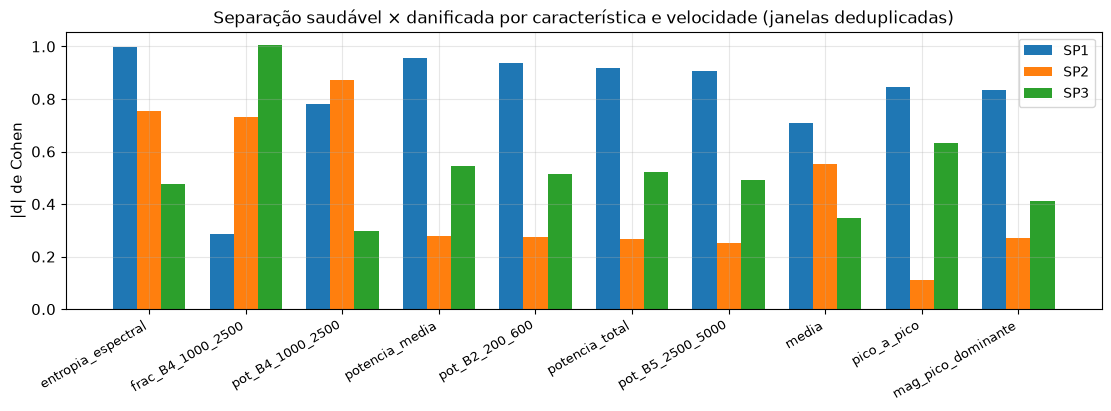

In [25]:
# Figura: |d| de Cohen das características mais fortes, por SP
top_feats = (sep.groupby('caracteristica')['cohen_d_abs'].mean().nlargest(10).index.tolist())
fig, ax = plt.subplots(figsize=(11, 4))
larg = 0.25
for i, sp in enumerate([1, 2, 3]):
    vals = [sep[(sep.velocidade == sp) & (sep.caracteristica == ft)].cohen_d_abs.iloc[0]
            for ft in top_feats]
    ax.bar(np.arange(len(top_feats)) + (i - 1) * larg, vals, larg, label=f'SP{sp}')
ax.set_xticks(range(len(top_feats)))
ax.set_xticklabels(top_feats, rotation=30, ha='right', fontsize=9)
ax.set_ylabel('|d| de Cohen')
ax.set_title('Separação saudável × danificada por característica e velocidade (janelas deduplicadas)')
ax.legend()
salvar_figura(fig, 'comp_separabilidade')
plt.show()

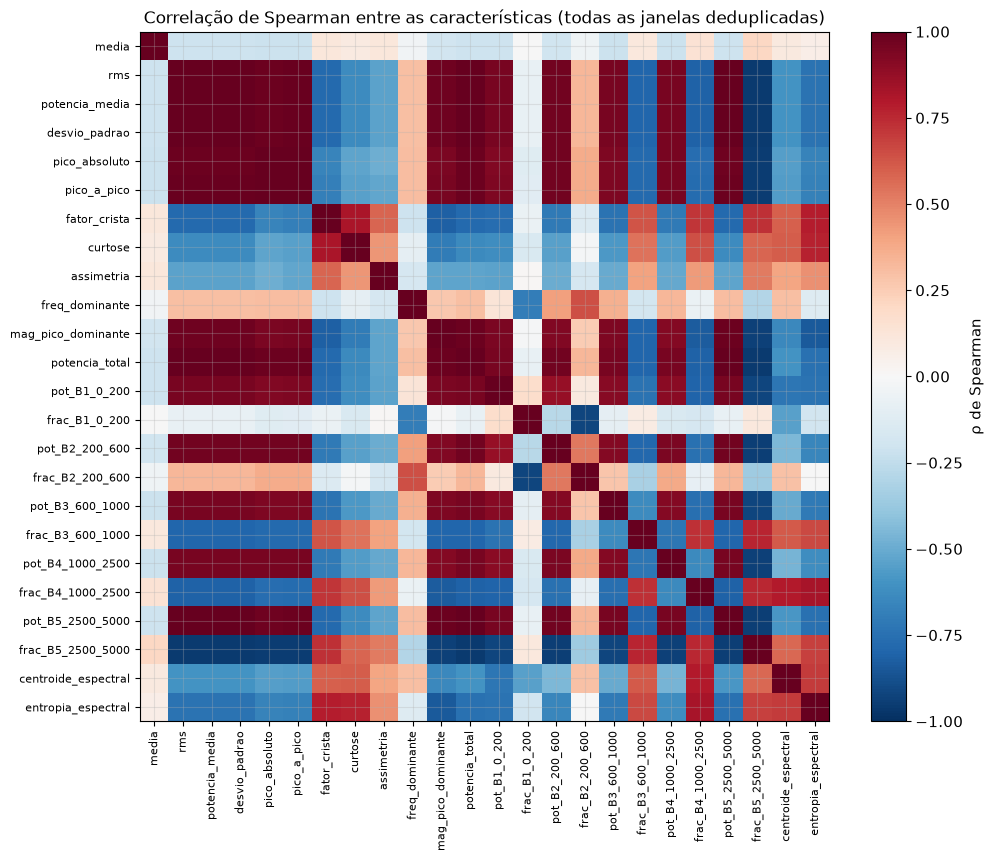

77 pares com |ρ| > 0,9. Os 12 mais fortes:
  ('rms', 'potencia_media', np.float64(1.0))
  ('rms', 'desvio_padrao', np.float64(1.0))
  ('potencia_media', 'desvio_padrao', np.float64(1.0))
  ('potencia_total', 'pot_B5_2500_5000', np.float64(0.997))
  ('rms', 'potencia_total', np.float64(0.996))
  ('potencia_media', 'potencia_total', np.float64(0.996))
  ('desvio_padrao', 'potencia_total', np.float64(0.996))
  ('pico_absoluto', 'pico_a_pico', np.float64(0.996))
  ('rms', 'pot_B5_2500_5000', np.float64(0.993))
  ('potencia_media', 'pot_B5_2500_5000', np.float64(0.993))
  ('desvio_padrao', 'pot_B5_2500_5000', np.float64(0.993))
  ('rms', 'pico_a_pico', np.float64(0.986))


In [26]:
# Redundância: matriz de correlação de Spearman (tempo + frequência) e pares |rho| > 0,9
corr = df_dedup[feats].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(feats))); ax.set_xticklabels(feats, rotation=90, fontsize=8)
ax.set_yticks(range(len(feats))); ax.set_yticklabels(feats, fontsize=8)
fig.colorbar(im, label='ρ de Spearman')
ax.set_title('Correlação de Spearman entre as características (todas as janelas deduplicadas)')
salvar_figura(fig, 'comp_correlacao')
plt.show()

pares = [(f1_, f2_, round(corr.loc[f1_, f2_], 3))
         for i, f1_ in enumerate(feats) for f2_ in feats[i + 1:]
         if abs(corr.loc[f1_, f2_]) > 0.9]
print(f'{len(pares)} pares com |ρ| > 0,9. Os 12 mais fortes:')
for p in sorted(pares, key=lambda q: -abs(q[2]))[:12]:
    print(' ', p)

### 4.2 Dois achados sustentados por gráficos e medidas

**Achado 1 — a intensidade temporal mede velocidade, não condição.** O RMS cresce quase 10× de SP1 a SP3 (boxplots da Seção 2) e separa perfeitamente as velocidades; mas, como separador de condição dentro de cada SP, é fraco e **muda de direção**: a danificada tem RMS mediano 15 % maior em SP3 e 38 % **menor** em SP1 (|d| ≈ 0,83 em SP1, 0,28 em SP2, 0,57 em SP3; AUC ≤ 0,63). Um detector de defeito baseado só em "vibrou mais" erraria sistematicamente em SP1 e teria pouca margem em SP2.

**Achado 2 — a assinatura espectral da condição é estrutural e mais estável.** A entropia espectral é maior na danificada em **todas** as velocidades (medianas 0,61×0,53 / 0,53×0,50 / 0,43×0,37; |d| médio 0,74, AUC média 0,71 — a melhor característica geral), e a fração de potência em 1000–2500 Hz atinge |d| ≈ 0,87–1,01 em SP2/SP3 (AUC ≈ 0,75). Isso é coerente com o que os espectros médios mostram (fundamental deslocada ~4–5 % para baixo e energia espalhada em lombadas largas) e **não é visível no domínio do tempo**.

Nenhum dos dois domínios "vence" sempre: em SP1 as características de intensidade (potência, RMS) estão entre as melhores (|d| ≈ 0,8–0,96, ainda que com AUC modesta ≈ 0,59), enquanto em SP2/SP3 as espectrais relativas dominam — confirmando que não se deve presumir superioridade espectral a priori.

### 4.3 Redundância e conjunto proposto para a classificação (sem treinamento)

A matriz de Spearman mostra grupos de características intercambiáveis:
- **{RMS, potência média, desvio padrão}**: ρ = 1,000 entre si (identidades matemáticas com μ ≈ 0);
- **{pico absoluto, pico a pico}**: ρ = 0,996;
- **potências absolutas por banda × RMS/potência total**: ρ > 0,94 — todas crescem juntas com a velocidade; a informação específica de cada banda está nas **frações**;
- **frac_B1 × frac_B2**: ρ = −0,92 (somam quase 1 junto com as demais — uma é quase o complemento da outra).

**Conjunto proposto para a 2ª entrega** (justificativa, nenhum modelo treinado aqui):
- *Temporais:* **RMS** (representa o grupo de intensidade), **pico absoluto**, **fator de crista**, **curtose**, **assimetria**;
- *Espectrais:* **entropia espectral**, **centroide espectral**, **frequência dominante**, **frações de potência em B1, B2 e B4** (B3 e B5 têm pouca potência e frac_B5 é quase o espelho do RMS, ρ ≈ −0,96; frac_B1 mantida junto de frac_B2 por ser a divisão fundamental × harmônicos).

A **média** foi excluída apesar de |d| ≈ 0,55 em SP2: num acelerômetro piezoelétrico ela não carrega informação física de vibração (offset residual do condicionamento do sinal), e usá-la arriscaria aprender um artefato de aquisição da sessão em vez do estado da hélice.

## Seção 5 — Investigação adicional (req. 3.6)

**Pergunta:** *Como a velocidade de operação (SP1 → SP2 → SP3) modifica os picos espectrais e a separação entre hélices saudáveis e danificadas?*

**Justificativa e método.** As Seções 2–4 mostraram que a velocidade é o fator dominante nos sinais; resta caracterizar **como** ela desloca a estrutura espectral e se a distinção saudável × danificada fica mais fácil ou mais difícil conforme a velocidade. Método: (i) extrair os 5 maiores picos (≤ 1 000 Hz) dos espectros médios por condição × SP e verificar as razões entre as frequências (estrutura harmônica); (ii) acompanhar a fundamental por condição ao longo das SPs; (iii) comparar a separabilidade univariada (Seção 4) entre as SPs.

Razões entre as frequências dos 5 maiores picos e a fundamental (menor pico forte):
SP1 saudavel   : fundamental ≈  56.0 Hz | razões: 1.00, 2.00, 4.00, 6.04
SP1 danificada : fundamental ≈  52.0 Hz | razões: 1.00, 1.15, 1.98, 2.17, 4.15
SP2 saudavel   : fundamental ≈  99.0 Hz | razões: 1.00, 2.02, 2.99, 3.98, 4.97
SP2 danificada : fundamental ≈  94.0 Hz | razões: 1.00, 1.96, 2.93, 3.89, 3.95
SP3 saudavel   : fundamental ≈ 133.0 Hz | razões: 1.00, 1.04, 2.00, 3.01, 3.12
SP3 danificada : fundamental ≈ 128.0 Hz | razões: 1.00, 1.05, 1.99, 2.94, 2.98


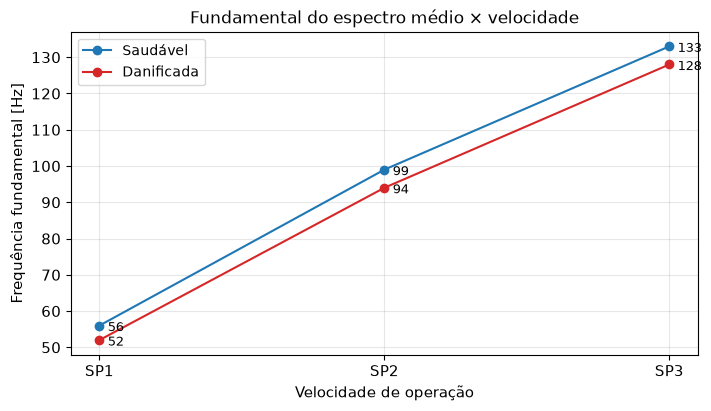

In [27]:
# (i) e (ii): fundamental e harmônicos por condição × velocidade
print('Razões entre as frequências dos 5 maiores picos e a fundamental (menor pico forte):')
fund = {}
for sp in [1, 2, 3]:
    for cond in ['saudavel', 'danificada']:
        freqs = sorted(ff for ff, _ in maiores_picos(espectros[f'{cond}_SP{sp}'], f_esp))
        freqs = [ff for ff in freqs if ff > 20]  # ignora resíduos de baixíssima frequência
        base = freqs[0]
        fund[(cond, sp)] = base
        print(f'SP{sp} {cond:11s}: fundamental ≈ {base:5.1f} Hz | razões: '
              + ', '.join(f'{ff / base:.2f}' for ff in freqs))

fig, ax = plt.subplots(figsize=(7, 4))
for cond in ['saudavel', 'danificada']:
    ax.plot([1, 2, 3], [fund[(cond, sp)] for sp in [1, 2, 3]], 'o-',
            color=CORES[cond], label=ROTULOS[cond])
    for sp in [1, 2, 3]:
        ax.annotate(f'{fund[(cond, sp)]:.0f}', (sp, fund[(cond, sp)]),
                    textcoords='offset points', xytext=(6, -4), fontsize=9)
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(['SP1', 'SP2', 'SP3'])
ax.set_xlabel('Velocidade de operação')
ax.set_ylabel('Frequência fundamental [Hz]')
ax.set_title('Fundamental do espectro médio × velocidade')
ax.legend()
salvar_figura(fig, 'invest_fundamental_sp')
plt.show()

In [28]:
# (iii) separabilidade × velocidade: melhores características em cada SP
print('Melhor característica e |d| por velocidade:')
for sp in [1, 2, 3]:
    melhor = sep[sep.velocidade == sp].nlargest(3, 'cohen_d_abs')
    print(f'SP{sp}:')
    for _, r in melhor.iterrows():
        print(f"   {r.caracteristica:22s} |d| = {r.cohen_d_abs:.2f}  AUC = {r.auc:.2f}")
print('\n|d| médio das 5 melhores características de cada SP:')
print({f'SP{sp}': round(sep[sep.velocidade == sp].nlargest(5, 'cohen_d_abs').cohen_d_abs.mean(), 2)
       for sp in [1, 2, 3]})

Melhor característica e |d| por velocidade:
SP1:
   entropia_espectral     |d| = 1.00  AUC = 0.76
   potencia_media         |d| = 0.96  AUC = 0.59
   pot_B2_200_600         |d| = 0.94  AUC = 0.62
SP2:
   pot_B4_1000_2500       |d| = 0.87  AUC = 0.75
   entropia_espectral     |d| = 0.75  AUC = 0.69
   frac_B4_1000_2500      |d| = 0.73  AUC = 0.72
SP3:
   frac_B4_1000_2500      |d| = 1.01  AUC = 0.77
   frac_B5_2500_5000      |d| = 0.66  AUC = 0.67
   pico_a_pico            |d| = 0.63  AUC = 0.65

|d| médio das 5 melhores características de cada SP:
{'SP1': np.float64(0.94), 'SP2': np.float64(0.7), 'SP3': np.float64(0.7)}


**Conclusão da investigação.** (i) Os espectros têm estrutura harmônica em todas as velocidades: as razões entre picos são ≈ 1, 2, 3, 4, 5 vezes a fundamental (quase exatas em SP2: 1,00 / 2,02 / 2,99 / 3,98 / 4,97). (ii) A fundamental cresce de forma aproximadamente proporcional com a velocidade — saudável: 56 → 99 → 133 Hz; danificada: 52 → 94 → 128 Hz — e a razão entre as fundamentais das duas condições é estável (≈ 0,95), ou seja, **o dano reduz a frequência de rotação efetiva em ~5 % em todas as velocidades** (hipótese: perda aerodinâmica/balanceamento exigindo operação ligeiramente diferente; o RPM real não é documentado, então registramos o efeito sem afirmar o mecanismo). (iii) A separação saudável × danificada **não melhora monotonicamente com a velocidade**: cada SP tem seu próprio "melhor separador" (SP1: entropia espectral e potências, |d| ≈ 0,9–1,0; SP2: fração/potência em 1000–2500 Hz, |d| ≈ 0,87; SP3: fração em 1000–2500 Hz, |d| ≈ 1,0), e o |d| médio das 5 melhores características é parecido nas três velocidades (≈ 0,9 / 0,7 / 0,7). A velocidade muda **quais** características separam, mais do que **quanto** se consegue separar — um argumento para incluir registros de todas as SPs no treinamento dos classificadores da 2ª entrega.

## Seção 6 — Conclusões da 1ª entrega

1. **Dados íntegros e comparáveis.** 111 registros verificados (sem NaN, sem saturação, tempo uniforme, fs = 10 kHz); comparações sempre dentro da mesma SP e C. As duplicatas C1/C2 saudáveis foram detectadas e deduplicadas (`gravacao_fisica_id`); nenhum corte de transiente foi necessário. 5 280 janelas de 1 s extraídas, com 23 características cada.
2. **Tempo:** a intensidade (RMS/potência/desvio padrão, que são redundantes entre si) é dominada pela velocidade; como indicador de defeito é fraca e inverte de direção em SP1. RMS² = potência = σ² + μ²; no piezo RMS ≈ σ (μ ≈ 0), enquanto no eixo Z da IMU a gravidade responde por ~87 % da potência — ilustrando o efeito da componente média.
3. **Frequência (núcleo do trabalho):** espectros harmônicos com fundamental dependente da velocidade; o dano desloca a fundamental ~5 % para baixo, espalha energia (entropia espectral consistentemente maior na danificada) e redistribui potência entre bandas (melhores separadores: entropia espectral e fração em 1000–2500 Hz, |d| até ≈ 1,0, AUC ≈ 0,75). Demonstramos o compromisso de resolução espectral (Δf = 1/T) e o aliasing (pico de 403,6 Hz rebatido para 96,4 Hz a 500 Hz sem filtro; eliminado pela decimação com filtro).
4. **Limitações.** Unidade do piezo não documentada (u.a.); significado das configurações C não documentado; RPM não documentado (harmônicos discutidos como hipótese); desbalanceamento ≈ 3,9:1 entre janelas danificadas e saudáveis deduplicadas; uma única gravação por condição danificada (sem repetição), o que impede separar completamente "efeito da condição" de "efeito da sessão de aquisição"; duplicatas C1/C2 reduzem a diversidade real dos saudáveis.
5. **Próxima etapa.** A tabela `results/features_por_janela.csv` (uma linha por janela, com IDs e rótulo) e o conjunto de características proposto na Seção 4.3 deixam a classificação pronta para a 2ª entrega, que deverá separar treino/teste **por registro** (nenhuma janela do mesmo registro nos dois conjuntos) e tratar o desbalanceamento.

---
**Referências.** Ismail, M. A. A.; Elshaar, M. E.; Abdalla, A.; Quan, Q. (2024). *DronePropB: Ground Testing Dataset for Commercial Drones with Defective Propellers*. Mendeley Data, V1. DOI: 10.17632/xkvfjmm8zg.1 (CC BY 4.0). Informações de hardware (drone Quanser QDrone 2, hélices HQ Durable 7×4,5") provêm do artigo do dataset relacionado DronePropA (Data in Brief, 2025, DOI: 10.1016/j.dib.2025.111589) e são citadas aqui apenas como contexto.